# 06. Tool Calling 오류와 수정

서버가 `200 OK`를 돌려주는데 `tool_calls`가 비어 있다. 또는 인자가 이상하다. 또는 같은 요청이 스트리밍에서만 다르게 끝난다. 이 노트북은 그런 증상을 "모델이 이상하다"로 뭉뚱그리지 않고, 도구 호출이 지나는 여섯 층 중 어디서 생겼는지 찾는 연습입니다. Part 5에서 에이전트가 요청을 반복해 보내는 구조를 봤다면, 여기서는 그 요청 하나가 도구 호출로 바뀌는 과정이 어디서 어긋나는지를 봅니다.

이 노트북의 근거는 여러 종류이고 섞어 말하면 안 됩니다. v0.32.0의 실제 GLM 파서에 사람이 만든 문자열을 넣어 얻은 결과, 실제 tokenizer와 serving 제너레이터까지 함께 돌린 스트리밍 결과, Rust 파서 crate를 돌린 결과, 구조화 태그를 xgrammar에 넣어 본 결과, 그리고 소스를 읽어 얻은 추론입니다. 어느 것도 GPU 서버나 수업 Pod에서 관찰한 것이 아닙니다. 표마다 `근거 종류` 칸을 붙여 어느 쪽인지 밝힙니다.

## 학습 목표

- 도구 호출을 chat template, 생성, parser, schema 검증, 실행, 네트워크 여섯 층으로 나누고, 증상에서 층을 고른다.
- `--enable-auto-tool-choice`, `--tool-call-parser`, `--reasoning-parser` 세 플래그의 조합이 만드는 결과를 설명한다.
- GLM 파서가 얇은 껍질 클래스와 선언형 `ParserEngine`으로 나뉜 구조를 말하고, `tool_choice`와 strict 수준이 GLM에서 문서와 다르게 동작하는 이유를 설명한다.
- `finish_reason`을 정하는 규칙을 `tool_choice`, 엔진 종료, 스트리밍 여부로 나눠 읽고 실행 기록과 대조한다.
- Python 파서와 Rust 파서의 차이를 말하고, 실행 결과와 코드 읽기 추론을 구분해 진단표를 쓴다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | 여섯 층 지도 | 5 |
| 1 | 세 플래그의 조합 | 7 |
| 2 | 파서의 구조 | 7 |
| 3 | 구성 문자열로 본 파서 결과 | 11 |
| 4 | `tool_choice`와 strict 수준 | 8 |
| 5 | `finish_reason` | 6 |
| 6 | reasoning 파서와의 상호작용 | 4 |
| 7 | Python 경로와 Rust 경로 | 4 |
| 8 | 진단표와 `RUN_POD` | 5 |
| 9 | 직접 해보기, 확인 질문, 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 코드 셀은 네트워크를 부르지 않습니다. 예외는 절 8의 `RUN_POD = False` 보호 셀 하나뿐이고, 기본값에서는 아무것도 보내지 않습니다.

## 0. 여섯 층 지도

도구 호출은 한 번의 "모델 답변"이 아니라 여섯 층을 차례로 지나는 일입니다. 층마다 실패의 모양과 고치는 사람이 다릅니다.

| 층 | 하는 일 | 누가 | 이 층에서 나는 실패의 모양 |
|---|---|---|---|
| template | `tools`와 이전 턴의 호출·결과를 프롬프트 문자열로 렌더링 | 체크포인트에 든 chat template | 모델이 호출 형식을 잃을 수 있다(C11, 가설). 인자가 JSON 객체가 아니면 서버가 `{}`로 바꾼다. 템플릿은 v0.32.0 소스가 아니라 체크포인트에 있다 |
| 생성 | 모델이 호출 마크업을 token으로 쓴다 | 모델과 sampling, 구조화 태그 | 잘림(`max_tokens`), 마크업 누락, 제약이 빠져 일반 텍스트가 나옴 |
| parser | 생성된 text에서 reasoning, content, `tool_calls`를 갈라냄 | API server 프로세스([vllm/entrypoints/openai/chat_completion/serving.py:997](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L997) 근처, 스트리밍은 [vllm/entrypoints/openai/chat_completion/serving.py:666](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L666) 근처) | 호출이 조용히 사라지거나 일부만 나옴 |
| schema 검증 | 인자가 도구 스키마에 맞는지 확인 | 서버는 하지 않는 것으로 읽힘, client 몫 | 틀린 타입, 빠진 필수 인자가 도구까지 감 |
| 실행 | client가 도구 함수를 부름 | 에이전트 client 코드 | 예외, 시간 초과로 루프가 멈춤(C12) |
| 네트워크 | 요청이 서버에 닿고 응답이 돌아옴 | 서버 플래그, 프록시, frontend | 400 응답, 연결 끊김 |

parser 층이 API server 프로세스에서 detokenize가 끝난 text에 적용된다는 점은 P6-32에, 엔진 기반 파서가 `skip_special_tokens`를 거짓으로 바꾼다는 점은 P6-36에 있습니다. `<tool_call>` 같은 마크업은 GLM-5.3-Flash tokenizer에서 한 token씩이지만 `all_special_tokens`에 들지 않습니다. 실제 tokenizer로 확인한 값입니다(절 6의 표, P6-36).

### 이 노트북이 말하는 방식

이 노트북의 주장은 소스를 읽어 얻은 것이거나 실제 코드를 CPU에서 돌려 얻은 것이고, 서버를 띄워 확인한 항목은 없습니다. 클래스를 호출한 것과 서버를 돌린 것은 다릅니다. 그래서 실패 사례 후보 C1부터 C12는 이 노트북 어디에서도 "관찰됐다"고 쓰지 않습니다. 표의 `근거 종류` 칸은 다음 중 하나를 말합니다.

- `실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님`: v0.32.0의 파서 클래스를 가짜 vocab으로 CPU에서 돌려, 사람이 만든 문자열을 넣어 얻은 비스트리밍 결과입니다(`data/reference_parser.json`). 파서 층에 한해 "그 입력에서 그렇게 나온다"가 사실입니다.
- `실제 클래스 실행, 구성 문자열`: 실제 파서, 실제 tokenizer, 실제 serving 제너레이터에 사람이 만든 문자열을 넣은 결과입니다(`data/reference_parser_stream.json`, `docs/reference/parser_stream.md`). 스트리밍과 비스트리밍을 모두 돌렸습니다. 엔진과 모델은 돌리지 않았고 엔진 종료(`stop`, `length`)도 사람이 정했습니다.
- `실제 클래스 실행, xgrammar 입력 시험`: GLM 구조화 태그를 xgrammar로 컴파일해 입력 token을 하나씩 대 본 결과입니다(같은 기록). 엔진이 sampling 마스크로 집행한 결과가 아닙니다.
- `실제 클래스 실행, Rust 파서 crate, 구성 문자열`: Rust 파서 crate만 돌린 결과입니다(`data/reference_parser_rust.json`, `docs/reference/parser_rust.md`). tokenizer는 시험용 대체물이고 chat 층과 HTTP 응답은 돌리지 않았습니다.
- `코드 읽기`: 소스를 읽어 얻은 추론입니다. 실행하지 않았습니다.

### 수업 서버와의 차이

이 노트북의 경로 설명은 v0.32.0의 Python frontend 기준입니다. GLM-5.3-Flash 레시피의 기본 명령은 Rust frontend를 켜는 변수를 넣고 있고(P6-28), 수업 Pod의 frontend와 명령은 확인되지 않았습니다. 그래서 "수업 서버가 이렇게 동작한다"고는 쓰지 않습니다. 절 7에서 다시 다룹니다.

**왜 이렇게 설계했나.** (수업의 해석) 여섯 층은 vLLM의 설계가 아니라 이 수업이 진단을 위해 나눈 구분입니다. 증상이 같아도 층이 다르면 고치는 곳이 달라지므로, 층 이름을 진단표의 첫 열로 씁니다.


In [1]:
import json
import pathlib
import tempfile

import pandas as pd
from IPython.display import display

from vllm_lab import DATA_DIR, view, agent_sim
from vllm_lab.agent_sim import (CaseNotRun, finish_reason_rule, flag_matrix, get_parser_case, load_parser_cases,
                                parser_case_table, reference_status, validate_tool_args)

print("agent_sim 이 모델링하지 않은 것 (이 노트북과 관계있는 줄):")
for line in agent_sim.NOT_MODELED:
    if "P5-" not in line:
        print(" -", line)

agent_sim 이 모델링하지 않은 것 (이 노트북과 관계있는 줄):
 - 실제 chat template과 실제 tokenizer는 쓰지 않습니다. 렌더링은 이 파일의 toy 규칙입니다.
 - 실제 서버의 tool 파서 실행은 하지 않습니다. 파서 결과는 reference_parser.json을 읽을 때만 나옵니다.


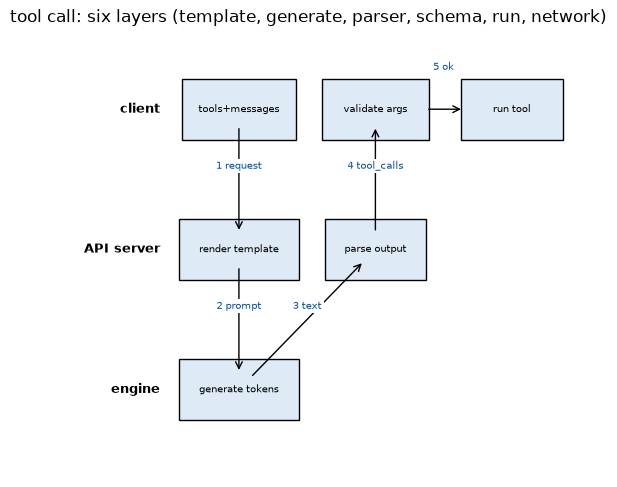

In [2]:
fig = view.lane_diagram(
    {"client": ["tools+messages", "validate args", "run tool"],
     "API server": ["render template", "parse output"],
     "engine": ["generate tokens"]},
    arrows=[("tools+messages", "render template", "1 request"),
            ("render template", "generate tokens", "2 prompt"),
            ("generate tokens", "parse output", "3 text"),
            ("parse output", "validate args", "4 tool_calls"),
            ("validate args", "run tool", "5 ok")],
    title="tool call: six layers (template, generate, parser, schema, run, network)")
fig

**관찰할 것.** 그림에서 `validate args`와 `run tool`은 client 줄에 있습니다. vLLM 서버 안에는 이 두 상자가 없습니다. 서버가 200을 돌려줬다는 사실은 parser 층까지 통과했다는 뜻이지, 인자가 맞다는 뜻이 아닙니다. 그림 글자가 ASCII뿐인 것은 글꼴이 없어도 깨지지 않게 하려는 도구의 규칙입니다.

## 1. 세 플래그의 조합

레시피는 도구 호출을 쓰려면 `--tool-call-parser glm47`, `--enable-auto-tool-choice`, `--reasoning-parser glm47` 세 가지를 함께 주라고 합니다(P6-03). 이 중 앞의 둘은 한쪽만 주면 서로 다른 방식으로 어긋납니다.

**개념.** 두 플래그는 이름이 비슷하지만 역할이 다릅니다. `--tool-call-parser`는 어떤 파서 클래스를 쓸지 고르는 값이고, `--enable-auto-tool-choice`는 모델이 스스로 도구를 고르는 `auto` 모드를 켜는 스위치입니다.

**공식 문서.** 문서는 자동 도구 선택에 두 플래그가 모두 필요하다고 안내합니다([docs/features/tool_calling.md:163](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L163) 근처의 플래그 목록). 한쪽만 줬을 때 무슨 일이 생기는지는 문서에 없습니다.

**코드.** 세 곳을 읽습니다.

- `validate_parsed_serve_args`([vllm/entrypoints/launchers/cli_args.py:523-524](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/cli_args.py#L523-L524))는 `--enable-auto-tool-choice`가 있고 파서 이름이 없으면 `TypeError`를 냅니다(P6-08). 서버가 뜨지 않습니다.
- `get_tool_parser`([vllm/parser/parser_manager.py:36-37](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/parser_manager.py#L36-L37))는 `auto` 스위치가 꺼져 있거나 파서 이름이 없으면 파서를 풀지 않고 돌려줍니다(P6-09).
- 두 플래그가 모두 없는 서버에 `tools`를 보내면, `tool_choice`를 생략해도 `check_tool_usage`([vllm/entrypoints/openai/chat_completion/protocol.py:953-954](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L953-L954))가 `auto`로 채우고, 렌더링 단계의 `tool_parsing_unavailable`([vllm/renderers/online_renderer.py:253-270](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/online_renderer.py#L253-L270))에서 오류 응답이 만들어집니다(P6-10). `none`은 통과합니다. 기본 오류 상태가 400이라는 점도 코드 읽기이고, 실제 응답 본문은 아무도 받아 보지 않았습니다.

레시피 쪽 근거인 R-04(미확인)는 수업 Pod가 이 플래그로 떴는지 README에 없다는 점입니다. 노트북은 `tools=`를 보내 `tool_calls`가 실제로 오는지로 확인하라고 안내합니다(절 8).


이제 `vllm_lab.agent_sim`의 표를 봅니다. **이것은 vLLM이 아니라 수업용 모델입니다.** `flag_matrix()`는 위 코드 읽기를 표로 옮긴 것일 뿐, 서버를 시작하거나 요청을 보내지 않습니다. 실제 서버의 파서 실행, chat template, tokenizer는 모델링하지 않았습니다.

**먼저 예측하세요.** `--tool-call-parser`만 주고 `--enable-auto-tool-choice`를 안 준 서버는 시작에 실패할까요, 성공할까요? 성공한다면 `tools`를 보냈을 때 어느 단계에서 어떻게 보일지 한 줄로 적고 아래 표의 해당 행을 읽으세요.

In [3]:
view.table(flag_matrix())

,--enable-auto-tool-choice,--tool-call-parser,시작 단계,tool_choice=auto 요청,근거 ID,근거 종류
0,True,True,정상 시작,파서가 호출을 추출한다,P6-03,코드 읽기
1,True,False,TypeError로 시작 실패(cli_args.py:523),서버가 뜨지 않아 요청할 수 없다,P6-08,코드 읽기
2,False,True,오류 없이 시작(parser_manager.py:36),도구 파싱이 꺼진다. tools가 있으면 400 문구가 난다(P6-10),P6-09,코드 읽기
3,False,False,오류 없이 시작,"tool_choice=none은 통과. 그 밖에는 400 BadRequestError, ""auto"" tool choice requires --enable-auto-tool-choice and --tool-ca...",P6-10,코드 읽기


**관찰할 것.** `시작 단계` 칸에서 시작 실패가 나는 행은 하나뿐입니다. 나머지 세 행은 서버가 정상으로 뜹니다. 그리고 `근거 종류` 칸이 네 행 모두 `코드 읽기`입니다. 네 조합을 실제로 띄워 본 기록은 이 수업에 없습니다.

**결론(코드 읽기).** `--tool-call-parser`만 주면 시작 오류는 없지만 파서가 None이 되어, `tools`를 보내는 첫 요청에서 앞의 400이 납니다. 조용히 지나가는 것은 `tools`가 없거나 `tool_choice`가 `none`일 때뿐입니다([vllm/renderers/online_renderer.py:253](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/online_renderer.py#L253)).

**진단의 함정.** 서버는 멀쩡히 뜨고 첫 `tools` 요청에서야 400이 납니다. `tools` 없는 요청은 정상이라 상태 점검만으로는 드러나지 않습니다.


In [4]:
# 400 문구가 나오는 조건을 코드 읽기 표로 옮긴다. 실행한 결과가 아니다.
rows = [
    {"서버 상태": "두 플래그 모두 없음", "tool_choice": "auto(생략해도 채워짐)", "tools": "있음",
     "응답": "400, 문구: \"auto\" tool choice requires --enable-auto-tool-choice and --tool-call-parser to be set",
     "근거 ID": "P6-10", "근거 종류": "코드 읽기"},
    {"서버 상태": "두 플래그 모두 없음", "tool_choice": "required 또는 이름 지정", "tools": "있음",
     "응답": "400, 문구는 --tool-call-parser to be set 쪽", "근거 ID": "P6-10", "근거 종류": "코드 읽기"},
    {"서버 상태": "두 플래그 모두 없음", "tool_choice": "none", "tools": "있음",
     "응답": "통과(도구 호출 없이 일반 생성)", "근거 ID": "P6-10", "근거 종류": "코드 읽기"},
    {"서버 상태": "--tool-call-parser만", "tool_choice": "auto", "tools": "있음",
     "응답": "파서가 None이라 위와 같은 400", "근거 ID": "P6-09, P6-10", "근거 종류": "코드 읽기"},
]
view.table(rows)

,서버 상태,tool_choice,tools,응답,근거 ID,근거 종류
0,두 플래그 모두 없음,auto(생략해도 채워짐),있음,"400, 문구: ""auto"" tool choice requires --enable-auto-tool-choice and --tool-call-parser to be set",P6-10,코드 읽기
1,두 플래그 모두 없음,required 또는 이름 지정,있음,"400, 문구는 --tool-call-parser to be set 쪽",P6-10,코드 읽기
2,두 플래그 모두 없음,none,있음,통과(도구 호출 없이 일반 생성),P6-10,코드 읽기
3,--tool-call-parser만,auto,있음,파서가 None이라 위와 같은 400,"P6-09, P6-10",코드 읽기


## 2. 파서의 구조

**개념.** GLM 도구 호출은 `<tool_call>함수명<arg_key>키</arg_key><arg_value>값</arg_value></tool_call>` 모양의 XML 비슷한 마크업입니다. 모델은 JSON을 쓰지 않습니다. 인자 JSON은 파서가 만듭니다(P6-18).

**공식 문서.** 문서는 `glm45`는 4.5와 4.6용, `glm47`은 4.7용으로 나눠 안내합니다([docs/features/tool_calling.md:434](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L434) 근처). 구현이 같다는 말은 없습니다.

**코드.**

- 이름 `glm45`와 `glm47`은 도구 파서 레지스트리에서 같은 클래스 `Glm47MoeModelToolParser`를 가리킵니다([vllm/tool_parsers/__init__.py:61](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/__init__.py#L61), [vllm/tool_parsers/__init__.py:65](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/__init__.py#L65)). reasoning 파서 쪽도 두 이름이 같은 `Glm47MoeParserReasoningAdapter`입니다([vllm/reasoning/__init__.py:59](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/reasoning/__init__.py#L59), [vllm/reasoning/__init__.py:63](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/reasoning/__init__.py#L63)). Python 서버에서는 어느 이름을 써도 같은 클래스가 로드됩니다(P6-01, P6-02). Rust frontend에서는 이름이 구현을 가릅니다. 차이는 절 7의 표에서 읽습니다(P6-04).
- `glm47_moe_tool_parser.py`는 14줄이고 세 값만 정합니다([vllm/tool_parsers/glm47_moe_tool_parser.py:10](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/glm47_moe_tool_parser.py#L10)에서 클래스, [vllm/tool_parsers/glm47_moe_tool_parser.py:11](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/glm47_moe_tool_parser.py#L11)에서 `supports_required_and_named = False`, [vllm/tool_parsers/glm47_moe_tool_parser.py:12](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/glm47_moe_tool_parser.py#L12)에서 구조화 태그 모델 이름, [vllm/tool_parsers/glm47_moe_tool_parser.py:14](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/glm47_moe_tool_parser.py#L14)에서 기본 strict 수준 `FUNCTION`). 파싱 로직은 없습니다(P6-05).
- 실제 파싱은 `ParserEngine` 위에 만든 `Glm47MoeParser`([vllm/parser/glm47_moe.py:203](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L203))가 합니다. 모듈 머리말([vllm/parser/glm47_moe.py:3](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L3))이 reasoning과 tool call을 함께 다룬다고 밝힙니다. `Glm47MoeParserReasoningAdapter`와 `Glm47MoeParserToolAdapter`는 `make_adapters`([vllm/parser/engine/adapters.py:235](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/adapters.py#L235))를 한 번 불러 한 파서에서 만들어 냅니다([vllm/parser/engine/registered_adapters.py:95-98](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/registered_adapters.py#L95-L98), P6-06).
- 엔진 기반 파서는 `adjust_request`([vllm/parser/engine/parser_engine.py:227-231](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L227-L231))에서 요청의 `skip_special_tokens`를 거짓으로 바꿉니다. GLM-5.3-Flash tokenizer에서 마크업은 `all_special_tokens`에 들지 않아 이 값과 상관없이 남습니다. 이 값으로 지워지는 것은 `<|observation|>` 같은 특수 token입니다(실제 tokenizer 실행, P6-36).
- 서빙 쪽에서 비스트리밍은 `parser.parse`([vllm/entrypoints/openai/chat_completion/serving.py:998](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L998))를, 스트리밍은 조각마다 `parser.parse_delta`([vllm/entrypoints/openai/chat_completion/serving.py:667](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L667))를 부릅니다(P6-32).

이 노트북은 `hermes_tool_parser.py`로 GLM을 설명하지 않습니다. 그 파일은 GLM 경로가 아닙니다.

파서 동작을 확인하려면 껍질 파일이 아니라 `glm47_moe.py`와 `parser_engine.py`를 읽어야 합니다.


In [5]:
rows = [
    {"설정 이름": "--tool-call-parser glm45", "로드되는 클래스": "Glm47MoeModelToolParser", "파일": "vllm/tool_parsers/glm47_moe_tool_parser.py:10", "근거 ID": "P6-01"},
    {"설정 이름": "--tool-call-parser glm47", "로드되는 클래스": "Glm47MoeModelToolParser", "파일": "vllm/tool_parsers/glm47_moe_tool_parser.py:10", "근거 ID": "P6-01"},
    {"설정 이름": "--reasoning-parser glm45", "로드되는 클래스": "Glm47MoeParserReasoningAdapter", "파일": "vllm/reasoning/__init__.py:59", "근거 ID": "P6-02"},
    {"설정 이름": "--reasoning-parser glm47", "로드되는 클래스": "Glm47MoeParserReasoningAdapter", "파일": "vllm/reasoning/__init__.py:63", "근거 ID": "P6-02"},
    {"설정 이름": "(두 어댑터가 감싸는 엔진 파서)", "로드되는 클래스": "Glm47MoeParser(ParserEngine)", "파일": "vllm/parser/glm47_moe.py:203", "근거 ID": "P6-06"},
]
for row in rows:
    row["근거 종류"] = "코드 읽기"
view.table(rows)

,설정 이름,로드되는 클래스,파일,근거 ID,근거 종류
0,--tool-call-parser glm45,Glm47MoeModelToolParser,vllm/tool_parsers/glm47_moe_tool_parser.py:10,P6-01,코드 읽기
1,--tool-call-parser glm47,Glm47MoeModelToolParser,vllm/tool_parsers/glm47_moe_tool_parser.py:10,P6-01,코드 읽기
2,--reasoning-parser glm45,Glm47MoeParserReasoningAdapter,vllm/reasoning/__init__.py:59,P6-02,코드 읽기
3,--reasoning-parser glm47,Glm47MoeParserReasoningAdapter,vllm/reasoning/__init__.py:63,P6-02,코드 읽기
4,(두 어댑터가 감싸는 엔진 파서),Glm47MoeParser(ParserEngine),vllm/parser/glm47_moe.py:203,P6-06,코드 읽기


In [6]:
# GLM 호출 마크업을 문자열로 조립만 한다. 파서를 돌리는 코드가 아니고, 모델 출력도 아니다.
name, pairs = "get_temperature", {"city": "서울"}
body = "".join(f"<arg_key>{key}</arg_key><arg_value>{value}</arg_value>" for key, value in pairs.items())
constructed = f"<tool_call>{name}{body}</tool_call>"
print(constructed)
print()
print("파서가 이 문자열에서 만들 인자 JSON(조립 규칙을 손으로 옮긴 것, 실행 결과 아님):",
      json.dumps(pairs, ensure_ascii=False))

<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>

파서가 이 문자열에서 만들 인자 JSON(조립 규칙을 손으로 옮긴 것, 실행 결과 아님): {"city": "서울"}


## 3. 구성 문자열로 본 파서 결과

여기부터는 실제 코드를 돌린 기록을 읽습니다. 먼저 `data/reference_parser.json`입니다. 이 노트북을 만들 때 v0.32.0 소스의 실제 reasoning 파서 `glm47`과 도구 파서 `glm47`을 CPU에서 돌렸습니다. 서빙의 비스트리밍 경로와 같은 순서로, 먼저 reasoning을 떼고 남은 content에 도구 파서를 적용했습니다(`extract_reasoning`, [vllm/parser/abstract_parser.py:841](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L841)). 통합 경로 `parse()`([vllm/parser/abstract_parser.py:833](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L833))도 같이 돌려 모든 케이스에서 같은 결과를 확인했습니다.

이 기록의 한계를 먼저 읽으세요. `parser.limit` 칸이 말하는 것을 그대로 출력합니다.

- 입력은 전부 사람이 만든 문자열입니다. 모델 출력이 아닙니다.
- 진짜 GLM tokenizer가 아니라 특수 token 14개만 가진 가짜 vocab을 썼습니다. 그래서 이 기록은 token ID로 판정하는 경로와 chat template 판정을 검증하지 못합니다.
- 이 기록은 스트리밍 경로를 돌리지 않았습니다.
- 이 기록은 Python 파서 기준입니다.
- GPU 서버나 수업 Pod의 결과가 아닙니다.

위의 빈 곳을 메우는 기록이 둘 더 있습니다. 아래 셀이 세 기록의 상태를 함께 출력합니다.

- `data/reference_parser_stream.json`(설명 `docs/reference/parser_stream.md`): 같은 8개 문자열, 잘린 문자열 3개, `tools`를 뺀 요청에 넣은 문자열 1개를 실제 tokenizer `zai-org/GLM-5.3-Flash`(revision `46a050b`, 가중치 없음)의 token으로 잘라 실제 `chat_completion_stream_generator`([vllm/entrypoints/openai/chat_completion/serving.py:466](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L466))와 `chat_completion_full_generator`([vllm/entrypoints/openai/chat_completion/serving.py:935](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L935))에 넣었습니다. 비스트리밍 결과는 8개 모두 가짜 vocab 기록과 같았습니다. token ID 판정과 chat template 판정도 이 기록에 있습니다.
- `data/reference_parser_rust.json`(설명 `docs/reference/parser_rust.md`): Rust 파서 crate만 같은 8개 문자열로 돌렸습니다.

어느 쪽도 엔진과 모델을 돌리지 않았습니다. 엔진 종료(`stop`, `length`)는 사람이 정한 값입니다.

In [7]:
status = reference_status()
print("reference_parser.json status:", status["status"], "| reason:", status["reason"])
print("tokenizer 대체물:", status["parser"]["tokenizer"])
print("한계:", status["parser"]["limit"])
print()

stream_record = json.loads((DATA_DIR / "reference_parser_stream.json").read_text(encoding="utf-8"))
stream_rows = {row["id"]: row for row in stream_record["cases"] + stream_record["extra_cases"]}
print("reference_parser_stream.json status:", stream_record["status"], "| 문자열 수:", len(stream_rows))
print("tokenizer:", stream_record["tokenizer"]["source"], stream_record["tokenizer"]["revision"][:7],
      "| 가중치 받음:", stream_record["tokenizer"]["weights_downloaded"])
print("근거:", stream_record["evidence"])
print("한계:", stream_record["limit"])
print()

rust_record = json.loads((DATA_DIR / "reference_parser_rust.json").read_text(encoding="utf-8"))
print("reference_parser_rust.json status:", rust_record["status"], "| 문자열 수:", len(rust_record["rows"]))
print("tokenizer:", rust_record["method"]["tokenizer"])
print("한계:", rust_record["method"]["limit"])

CLASS_RUN = "실제 클래스 실행, 구성 문자열"


def arguments_of(result):
    """스트리밍 또는 비스트리밍 결과의 첫 호출 arguments. 호출이 없으면 그렇게 적는다."""
    return result["tool_calls"][0]["arguments"] if result["tool_calls"] else "호출 없음"


def json_state(result):
    """호출의 arguments가 올바른 JSON인지. 호출이 없으면 '-'."""
    if not result["tool_calls"]:
        return "-"
    return "올바름" if all(result["arguments_json_valid"]) else "깨짐"

reference_parser.json status: ran | reason: None
tokenizer 대체물: StubTokenizer (특수 토큰 14개만 가진 가짜 vocab, 진짜 GLM tokenizer 아님)
한계: 문자열 경로만 검증한다. 진짜 vocab의 token ID 경로(is_reasoning_end, 토큰 ID 기반 종료 판정), chat template 판정(_glm53_always_thinks), 스트리밍은 실행하지 않았다.

reference_parser_stream.json status: ran | 문자열 수: 12
tokenizer: zai-org/GLM-5.3-Flash 46a050b | 가중치 받음: False
근거: 실제 GLM 파서, 실제 tokenizer, 실제 serving 제너레이터, 구성 문자열, 모델 출력 아님, 라이브 서버 아님
한계: 엔진과 모델을 돌리지 않았다. RequestOutput 조각과 엔진 종료(stop, length), 종료 토큰은 사람이 정했다. Python 파서만 돌렸고 Rust 파서는 돌리지 않았다. 구조화 태그는 xgrammar로 컴파일해 입력 토큰을 대 봤을 뿐 엔진의 sampling 마스크로 집행하지 않았다.

reference_parser_rust.json status: ran | 문자열 수: 8
tokenizer: vllm_tokenizer TestTokenizer with only <think>=256 and </think>=257, not the real GLM tokenizer
한계: Parser crates only. Chat layer, tool_choice handling, unified parser, real tokenizer, HTTP response shape were not run. Unknown-tool filtering was grepped in rust/src/chat and parser: no hit outside renderers, so not found,

위 출력의 세 status가 모두 `ran`입니다. 바로 아래 표는 첫 기록(`data/reference_parser.json`)을 읽고, 각 행에 `실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님`을 붙여 읽습니다. 그 기록이 `not_run`이었다면 `CaseNotRun` 오류로 멈추고 그 메시지에 이유가 들어 있으며, 그 절은 코드 읽기 표로 대신해야 합니다.

**먼저 예측하세요.** 아래 표에서 `unknown_tool`은 `tools`에 선언하지 않은 이름의 호출입니다. 결과가 (가) 오류 응답, (나) content에 마크업이 그대로 남음, (다) `tool_calls`가 빈 목록 중 무엇일지 적고 표를 읽으세요.

In [8]:
rows = []
for row in parser_case_table():
    rows.append({"id": row["id"], "후보": ",".join(row["후보"]) or "-", "제목": row["제목"],
                 "reasoning": row["reasoning"] or "(없음)", "content": row["content"] or "(없음)",
                 "tool_calls 개수": len(row["tool_calls"]) if isinstance(row["tool_calls"], list) else row["tool_calls"],
                 "근거 종류": "실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
                 if row["근거 종류"] == agent_sim.PARSER_EVIDENCE else row["근거 종류"]})
view.table(rows)

,id,후보,제목,reasoning,content,tool_calls 개수,근거 종류
0,clean_call,-,깨끗한 호출,(없음),(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
1,reasoning_then_call,-,생각 구간 뒤 호출,사용자가 서울 기온을 묻는다.,(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
2,malformed_markup,C7,</tool_call> 없이 다음 <tool_call>,(없음),(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
3,truncated_call,"C2,C6",닫히지 않은 호출,(없음),(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
4,unknown_tool,C3,tools에 없는 이름,(없음),(없음),0,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
5,bad_arg_type,C4,정수 인자에 숫자 아닌 값,(없음),(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
6,no_call,-,호출 없는 일반 답변(생각 구간 포함),도구가 필요한 질문이 아니다.,"안녕하세요, 무엇을 도와드릴까요?",0,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
7,no_call_missing_think_end,-,"호출 없는 일반 답변, </think> 없음(기본 thinking 상태의 결과)","안녕하세요, 무엇을 도와드릴까요?",(없음),0,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"


**관찰할 것.** `tool_calls 개수` 칸과 `content` 칸을 같이 읽으세요. `unknown_tool` 행은 오류가 아니라 호출 0개이고 content도 비어 있습니다. 응답이 "성공"이면서 호출이 없는 모양입니다. 또 `malformed_markup` 행은 호출이 둘 있었는데 하나만 남았습니다.

In [9]:
from IPython.display import display

rows = []
for case in load_parser_cases():
    out = case.output
    call_names = [call["name"] for call in out["tool_calls"]]
    arg_types = {}
    for call in out["tool_calls"]:
        parsed = json.loads(call["arguments"])
        arg_types.update({f"{call['name']}.{key}": type(value).__name__ for key, value in parsed.items()})
    rows.append({"id": case.id, "후보": ",".join(case.candidates) or "-", "층": case.layer,
                 "입력(구성 문자열)": case.raw_text, "선언한 도구": ",".join(case.tools),
                 "나온 호출": call_names, "arguments 값의 타입": arg_types or "-",
                 "tools_called": out["tools_called"]})
display(view.table(rows))
print("malformed_markup 입력 전체:", get_parser_case("malformed_markup").raw_text)

,id,후보,층,입력(구성 문자열),선언한 도구,나온 호출,arguments 값의 타입,tools_called
0,clean_call,-,parser,<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,get_temperature,[get_temperature],{'get_temperature.city': 'str'},True
1,reasoning_then_call,-,parser,사용자가 서울 기온을 묻는다.</think>\n<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,get_temperature,[get_temperature],{'get_temperature.city': 'str'},True
2,malformed_markup,C7,parser,<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value><tool_call>get_temperature<arg_key>city</a...,get_temperature,[get_temperature],{'get_temperature.city': 'str'},True
3,truncated_call,"C2,C6",parser,<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울,get_temperature,[get_temperature],-,True
4,unknown_tool,C3,parser,<tool_call>get_humidity<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,get_temperature,[],-,False
5,bad_arg_type,C4,parser,<tool_call>set_timer<arg_key>minutes</arg_key><arg_value>곧</arg_value><arg_key>label</arg_key><arg_value>라면</arg_val...,set_timer,[set_timer],"{'set_timer.minutes': 'str', 'set_timer.label': 'str'}",True
6,no_call,-,parser,"도구가 필요한 질문이 아니다.</think>안녕하세요, 무엇을 도와드릴까요?",get_temperature,[],-,False
7,no_call_missing_think_end,-,parser,"안녕하세요, 무엇을 도와드릴까요?",get_temperature,[],-,False


malformed_markup 입력 전체: <tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value><tool_call>get_temperature<arg_key>city</arg_key><arg_value>부산</arg_value></tool_call>


**관찰할 것.** `arguments 값의 타입` 칸에서 `bad_arg_type` 행을 찾으세요. 도구 스키마에서 `minutes`는 정수인데 파서가 낸 값의 타입이 문자열입니다. 파서는 변환에 실패하면 원래 문자열을 그대로 둡니다(P6-18). 이 행은 실제 파서의 결과이므로 "구성 문자열에 대해 v0.32.0 파서는 거르지 않았다"는 사실입니다. 같은 일이 실제 모델 출력에서 일어난다는 뜻은 아닙니다.

In [10]:
# 실패 재현: 존재하지 않는 케이스 ID, 그리고 실행하지 못한 기록(not_run)을 읽으려는 시도
try:
    get_parser_case("no_such_case")
except KeyError as error:
    print("KeyError:", error)

with tempfile.TemporaryDirectory() as folder:
    fake = pathlib.Path(folder) / "reference_parser.json"
    fake.write_text(json.dumps({"status": "not_run", "reason": "시험용 기록: 이 파일은 일부러 만든 not_run입니다.",
                                "parser": None, "cases": []}, ensure_ascii=False), encoding="utf-8")
    print("임시 기록의 status:", reference_status(fake)["status"])
    try:
        get_parser_case("clean_call", fake)
    except CaseNotRun as error:
        print("CaseNotRun:", error)

KeyError: "케이스 'no_such_case'가 기록에 없습니다."
임시 기록의 status: not_run
CaseNotRun: 파서 시험을 실행하지 못했습니다: 시험용 기록: 이 파일은 일부러 만든 not_run입니다.


**관찰할 것.** 두 번째 예외는 `ran` 기록이 없을 때 결과를 지어내지 않고 멈춘다는 약속입니다. 이 약속이 있어야 표의 `근거 종류` 칸을 믿을 수 있습니다. 위 임시 기록은 일부러 만든 것이고, 저장소의 `data/reference_parser.json`은 건드리지 않았습니다.

### 잘림이 만드는 네 가지 모양

`max_tokens`로 호출 중간에 끊기면(C2, C6) 어디서 끊겼는지에 따라 결과가 달라집니다. 코드는 이렇습니다. 출력이 끝나면 `finish()`([vllm/parser/engine/streaming_parser_engine.py:294](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/streaming_parser_engine.py#L294))가 열린 호출을 닫는 이벤트를 억지로 넣습니다([vllm/parser/engine/streaming_parser_engine.py:310-327](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/streaming_parser_engine.py#L310-L327)). 이어서 `_accept_tool_name`([vllm/parser/engine/parser_engine.py:1130](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L1130))이 이름이 선언된 도구인지 확인하고, 닫힌 `<arg_key>/<arg_value>` 쌍으로 인자를 만듭니다(P6-16). 비스트리밍에서는 닫히지 않은 마지막 쌍이 `_ARG_RE`([vllm/parser/glm47_moe.py:54-58](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L54-L58))에 걸리지 않아 사라집니다(P6-19). 스트리밍은 값을 먼저 내보냈으므로 사정이 다릅니다.

아래 표의 네 위치는 모두 실제 파서와 serving 제너레이터에 넣어 돌린 결과입니다. `코드 읽기 예상` 칸은 실행 전에 코드에서 읽은 내용이고, 뒤의 칸들이 실행값입니다. 입력은 사람이 만든 문자열이고 모델이 이렇게 끊긴 것이 아닙니다.

In [11]:
truncated = get_parser_case("truncated_call")
print("입력(구성 문자열):", truncated.raw_text)
print("가짜 vocab 기록의 tool_calls:", truncated.output["tool_calls"], "| tools_called:", truncated.output["tools_called"])
print()
positions = [
    ("함수명 중간", "truncated_mid_name", "이름이 선언 목록과 맞지 않아 호출이 버려진다"),
    ("함수명 뒤, 인자 쌍 시작 전", "truncated_after_name", "이름이 선언 목록과 맞으면 인자 {}인 호출이 나간다"),
    ("첫 인자의 값 중간(</arg_value> 없음)", "truncated_call", "비스트리밍에서는 닫힌 쌍이 없으니 인자 {}, 스트리밍은 값을 먼저 내보낸다"),
    ("닫힌 쌍 하나 뒤", "truncated_after_closed_pair", "비스트리밍에서는 닫힌 쌍만으로 호출이 나가고 끊긴 쌍은 사라진다, 스트리밍은 값을 먼저 내보낸다"),
]
rows = []
for where, case_id, expected in positions:
    row = stream_rows[case_id]
    rows.append({"끊긴 위치": where, "입력(구성 문자열)": row["raw_text"], "코드 읽기 예상": expected,
                 "비스트리밍 arguments": arguments_of(row["non_stream"]), "비스트리밍 JSON": json_state(row["non_stream"]),
                 "스트리밍 arguments": arguments_of(row["stream"]), "스트리밍 JSON": json_state(row["stream"]),
                 "근거 종류": CLASS_RUN})
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

입력(구성 문자열): <tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울
가짜 vocab 기록의 tool_calls: [{'name': 'get_temperature', 'arguments': '{}'}] | tools_called: True



,끊긴 위치,입력(구성 문자열),코드 읽기 예상,비스트리밍 arguments,비스트리밍 JSON,스트리밍 arguments,스트리밍 JSON,근거 종류
0,함수명 중간,<tool_call>get_temp,이름이 선언 목록과 맞지 않아 호출이 버려진다,호출 없음,-,호출 없음,-,"실제 클래스 실행, 구성 문자열"
1,"함수명 뒤, 인자 쌍 시작 전",<tool_call>get_temperature,이름이 선언 목록과 맞으면 인자 {}인 호출이 나간다,{},올바름,{},올바름,"실제 클래스 실행, 구성 문자열"
2,첫 인자의 값 중간(</arg_value> 없음),<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울,"비스트리밍에서는 닫힌 쌍이 없으니 인자 {}, 스트리밍은 값을 먼저 내보낸다",{},올바름,"{""city"": ""서울",깨짐,"실제 클래스 실행, 구성 문자열"
3,닫힌 쌍 하나 뒤,<tool_call>set_timer<arg_key>minutes</arg_key><arg_value>5</arg_value><arg_key>label</arg_key><arg_value>라,"비스트리밍에서는 닫힌 쌍만으로 호출이 나가고 끊긴 쌍은 사라진다, 스트리밍은 값을 먼저 내보낸다","{""minutes"": 5}",올바름,"{""minutes"": 5, ""label"": ""라",깨짐,"실제 클래스 실행, 구성 문자열"


**관찰할 것.** `첫 인자의 값 중간` 행에서 `비스트리밍 arguments`와 `스트리밍 arguments` 칸을 나란히 읽으세요. 비스트리밍은 `{}`이고 호출이 성립합니다. 스트리밍은 값을 먼저 내보냈으므로 `{"city": "서울`에서 끝나고 JSON이 아닙니다. `닫힌 쌍 하나 뒤` 행도 같은 방식으로 갈립니다. 호출이 나온 세 행 중에서는 `함수명 뒤` 행만 두 경로가 같습니다. 소스 주석(`_extract_tool_calls`, [vllm/parser/abstract_parser.py:474-481](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L474-L481))은 잘린 마크업을 버린다고 적지만, 이름이 맞으면 호출은 살아남습니다(P6-16). "호출이 왔다"와 "호출이 쓸 만하다"는 다릅니다.

In [12]:
unknown = get_parser_case("unknown_tool")
declared = list(unknown.tools)
unknown_stream = stream_rows["unknown_tool"]["stream"]
omitted = stream_rows["omitted_tools_call"]
empty_request = stream_record["tools_empty_array_request"]
rows = [
    {"상황": "선언하지 않은 이름의 호출(비스트리밍)", "입력": unknown.raw_text, "선언한 도구": declared,
     "결과": {"tool_calls": unknown.output["tool_calls"], "content": unknown.output["content"], "error": unknown.output["error"]},
     "설명": "호출이 버려지고 content도 빈다(P6-17)",
     "근거 종류": "실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"},
    {"상황": "선언하지 않은 이름의 호출(스트리밍)", "입력": stream_rows["unknown_tool"]["raw_text"], "선언한 도구": declared,
     "결과": {"tool_calls": unknown_stream["tool_calls"], "content": unknown_stream["content"], "deltas": unknown_stream["deltas"]},
     "설명": "이름 델타를 내보내지 않고 종료 때도 같은 검사로 걸러진다(P6-17)", "근거 종류": CLASS_RUN},
    {"상황": "요청에서 tools를 뺌", "입력": omitted["raw_text"], "선언한 도구": "-",
     "결과": {"tool_calls": omitted["non_stream"]["tool_calls"], "content": omitted["non_stream"]["content"]},
     "설명": "스트리밍, 비스트리밍 모두 호출도 content도 없다(P6-17)", "근거 종류": CLASS_RUN},
    {"상황": "요청의 tools가 빈 목록", "입력": "-", "선언한 도구": [],
     "결과": {"rejected": empty_request["rejected"], "error": empty_request["error"].replace("`", "")},
     "설명": "요청 검증에서 거절되어 파서까지 가지 않는다(P6-17)", "근거 종류": CLASS_RUN},
    {"상황": "파서 클래스에 tools=[]를 직접 넣음(API로 닿지 않는 경로)", "입력": unknown.raw_text, "선언한 도구": [],
     "결과": {"tool_calls": stream_record["tools_empty_parser_direct"]["tool_calls"]},
     "설명": "이름 검사를 하지 않아 호출이 나온다. 요청으로는 이 상태를 만들 수 없다", "근거 종류": CLASS_RUN},
]
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

,상황,입력,선언한 도구,결과,설명,근거 종류
0,선언하지 않은 이름의 호출(비스트리밍),<tool_call>get_humidity<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,[get_temperature],"{'tool_calls': [], 'content': None, 'error': None}",호출이 버려지고 content도 빈다(P6-17),"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"
1,선언하지 않은 이름의 호출(스트리밍),<tool_call>get_humidity<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,[get_temperature],"{'tool_calls': [], 'content': None, 'deltas': []}",이름 델타를 내보내지 않고 종료 때도 같은 검사로 걸러진다(P6-17),"실제 클래스 실행, 구성 문자열"
2,요청에서 tools를 뺌,<tool_call>get_humidity<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,-,"{'tool_calls': [], 'content': None}","스트리밍, 비스트리밍 모두 호출도 content도 없다(P6-17)","실제 클래스 실행, 구성 문자열"
3,요청의 tools가 빈 목록,-,[],"{'rejected': True, 'error': 'VLLMValidationError: tools must not be an empty array. Either provide at least one tool or omit the field entirely. (parameter=tools)'}",요청 검증에서 거절되어 파서까지 가지 않는다(P6-17),"실제 클래스 실행, 구성 문자열"
4,파서 클래스에 tools=[]를 직접 넣음(API로 닿지 않는 경로),<tool_call>get_humidity<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,[],"{'tool_calls': [{'name': 'get_humidity', 'arguments': '{""city"": ""서울""}'}]}",이름 검사를 하지 않아 호출이 나온다. 요청으로는 이 상태를 만들 수 없다,"실제 클래스 실행, 구성 문자열"


선언하지 않은 이름의 호출이 사라지고 content도 비는 것은 이 구성 문자열에서의 사실이고, 스트리밍과 비스트리밍이 같습니다(C3). 클라이언트에서 보이는 증상은 "`tool_calls`가 비었는데 `completion_tokens`는 크다"입니다. 모델이 일을 했는데 흔적이 없는 모양이라, 원문과 파싱 결과를 비교해야 합니다. `skip_special_tokens`는 엔진 기반 파서가 이미 거짓으로 바꾸므로(절 2) 요청에서 바꿔도 달라지지 않고, 원문을 보려면 서버 쪽 로그가 필요합니다. 다만 기본 구조화 태그의 문법은 이 이름을 거절합니다(절 4의 xgrammar 표, 엔진 집행은 실행하지 않음). 그래서 이 증상은 태그가 없는 서버의 이야기로 읽습니다.

빈 목록은 파서까지 오지 않습니다. `check_tool_usage`([vllm/entrypoints/openai/chat_completion/protocol.py:943-949](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L943-L949))가 요청 검증에서 `tools: []`를 거절합니다. 파서 안의 "도구 목록이 비면 이름 검사를 안 한다"는 분기는 파서 클래스를 직접 부를 때만 맞습니다(P6-17).

그러면 파서가 낸 인자는 믿을 수 있을까요? 서버가 필수 인자나 타입을 검증해 준다는 코드는 읽은 범위의 파서에서 찾지 못했습니다(P6-18, C5). xgrammar 재시험에서도 기본 얕은 태그는 필수 키가 빠진 호출을 통과시켰습니다(P6-27, 기록 파일에 저장하지 않음). 아래 `validate_tool_args`는 **vLLM 기능이 아니라** 이 수업이 만든 client 쪽 검증입니다. 실제 파서가 낸 `arguments`를 `tool_schemas`에 대 봅니다.

In [13]:
schemas = json.loads((DATA_DIR / "reference_parser.json").read_text(encoding="utf-8"))["tool_schemas"]
rows = []
for case in load_parser_cases():
    for call in case.output["tool_calls"]:
        problems = validate_tool_args(schemas[call["name"]], call["arguments"])
        rows.append({"케이스": case.id, "도구": call["name"], "arguments": call["arguments"],
                     "client 검증": problems or ["통과"],
                     "근거 종류": "실제 파서의 arguments + 수업용 검증 함수"})
view.table(rows)

,케이스,도구,arguments,client 검증,근거 종류
0,clean_call,get_temperature,"{""city"": ""서울""}",[통과],실제 파서의 arguments + 수업용 검증 함수
1,reasoning_then_call,get_temperature,"{""city"": ""서울""}",[통과],실제 파서의 arguments + 수업용 검증 함수
2,malformed_markup,get_temperature,"{""city"": ""부산""}",[통과],실제 파서의 arguments + 수업용 검증 함수
3,truncated_call,get_temperature,{},[필수 인자 'city'가 없습니다.],실제 파서의 arguments + 수업용 검증 함수
4,bad_arg_type,set_timer,"{""minutes"": ""곧"", ""label"": ""라면""}",[인자 'minutes'는 integer여야 하는데 str 값 '곧'입니다.],실제 파서의 arguments + 수업용 검증 함수


**관찰할 것.** `truncated_call`은 파서 쪽에서는 호출이 성립했지만 client 검증에서 필수 인자 `city`가 없다고 걸립니다. `bad_arg_type`은 `minutes`의 타입 불일치로 걸립니다. 나머지 케이스는 통과합니다. 검증 층이 서버에 없다면, 이 두 행은 client가 막지 않으면 도구까지 갑니다.

In [14]:
# 실패 재현: 검증 없이 파서가 낸 arguments를 그대로 도구에 넘긴다 (C4, C6, C7, C12)
def set_timer_unchecked(minutes, label=""):
    return f"{minutes + 1}분 뒤 알림({label})"      # 정수라고 믿고 계산한다

def set_timer_silent(minutes, label=""):
    return f"{label}: {'*' * 3}{minutes * 60}초"      # 문자열이어도 예외가 나지 않는다

bad = json.loads(get_parser_case("bad_arg_type").output["tool_calls"][0]["arguments"])
print("파서가 낸 인자(구성 문자열):", bad)
try:
    set_timer_unchecked(**bad)
except TypeError as error:
    print("검증 없이 실행 -> TypeError:", error)

print("틀린 값(예외 없음):", set_timer_silent(**bad))
print("맞는 입력일 때  :", set_timer_silent(minutes=3, label=bad["label"]))

problems = validate_tool_args(schemas["set_timer"], get_parser_case("bad_arg_type").output["tool_calls"][0]["arguments"])
print("검증을 끼우면   :", problems, "-> 모델에게 tool 메시지로 돌려보내 다시 시도시킨다")
print()
for case_id in ("truncated_call", "malformed_markup"):
    row = stream_rows[case_id]
    text = arguments_of(row["stream"])
    try:
        json.loads(text)
    except json.JSONDecodeError as error:
        print(f"{case_id} 스트리밍 arguments {text!r} -> JSONDecodeError: {error.msg}")
    print(f"{case_id} 비스트리밍 arguments {arguments_of(row['non_stream'])!r}")
    print("  client 검증(스트리밍):", validate_tool_args(schemas["get_temperature"], text))

파서가 낸 인자(구성 문자열): {'minutes': '곧', 'label': '라면'}
검증 없이 실행 -> TypeError: can only concatenate str (not "int") to str
틀린 값(예외 없음): 라면: ***곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧곧초
맞는 입력일 때  : 라면: ***180초
검증을 끼우면   : ["인자 'minutes'는 integer여야 하는데 str 값 '곧'입니다."] -> 모델에게 tool 메시지로 돌려보내 다시 시도시킨다

truncated_call 스트리밍 arguments '{"city": "서울' -> JSONDecodeError: Unterminated string starting at
truncated_call 비스트리밍 arguments '{}'
  client 검증(스트리밍): ['arguments가 JSON이 아닙니다: Unterminated string starting at (위치 9)']
malformed_markup 스트리밍 arguments '{"city": "서울' -> JSONDecodeError: Unterminated string starting at
malformed_markup 비스트리밍 arguments '{"city": "부산"}'
  client 검증(스트리밍): ['arguments가 JSON이 아닙니다: Unterminated string starting at (위치 9)']


**관찰할 것.** 첫 예외는 도구가 정수를 믿었기 때문에 나고, 두 번째 도구는 예외 없이 `곧`을 60번 반복한 문자열을 만들어 냅니다. 예외가 없는 실패가 더 위험합니다. 맞는 입력의 결과와 나란히 놓으면 차이가 보입니다. 검증 메시지를 모델에게 돌려주는 것이 에이전트 루프의 복구 경로입니다.

마지막 줄들은 같은 입력을 스트리밍으로 모은 인자입니다. `truncated_call`과 `malformed_markup` 모두 `json.loads`에서 실패합니다. 비스트리밍에서는 둘 다 올바른 JSON이고, `malformed_markup`은 남는 도시도 다릅니다. 구성 문자열을 실제 제너레이터에 넣은 결과이지 서버 응답이 아닙니다.

**왜 이렇게 설계했나.** (수업의 해석) 비스트리밍 경로에서는 파서가 키/값을 정규식으로 뽑아 `json.dumps`로 인자 JSON을 만들기 때문에 JSON 문법 오류로는 깨지지 않습니다(P6-18). 스트리밍은 닫히지 않은 값까지 조각으로 내보내고(`_compute_arg_delta`, [vllm/parser/engine/parser_engine.py:1031](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L1031), `_glm47_arg_converter`, [vllm/parser/glm47_moe.py:72-78](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L72-L78)), 끝에서 최종 변환이 이미 보낸 글자로 시작하지 않으면 나머지를 보내지 않습니다(`_flush_arg_converter`, [vllm/parser/engine/parser_engine.py:1076-1081](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L1076-L1081)). 이미 보낸 글자를 되돌릴 수 없기 때문이라고 읽습니다. 어느 경로도 값의 의미는 보장하지 않습니다. **수업의 권장.** 서버가 검증을 하지 않는다고 단정할 수는 없지만 읽은 범위에서 찾지 못했으므로, 검증은 client 몫으로 둡니다.

## 4. `tool_choice`와 strict 수준

**개념.** `tool_choice`는 `auto`(모델이 고른다), `required`(호출이 한 번 이상), 이름 지정(그 함수 하나), `none`(호출하지 않음) 네 가지입니다. 별개로 도구마다 `strict` 필드가 있고, 서버에는 `--tool-strict-level` 하한이 있습니다.

**공식 문서.** 이름 지정과 `required`는 구조화 출력(JSON 스키마)을 쓴다고 설명하고([docs/features/tool_calling.md:88](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L88)), `auto`는 `strict` 도구가 있을 때만 제약한다고 적습니다([docs/features/tool_calling.md:116](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L116)의 표 부근). 환경변수 `VLLM_ENFORCE_STRICT_TOOL_CALLING`의 설명([docs/features/tool_calling.md:137](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L137))과 서버 하한의 설명([docs/features/tool_calling.md:143](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L143))도 같은 문서에 있습니다.

**코드.** GLM에서는 이 설명 중 일부가 맞지 않습니다.

- `supports_required_and_named`가 거짓이면 `adjust_request`가 JSON 스키마 강제를 걸지 않고 요청을 그대로 돌려줍니다([vllm/tool_parsers/abstract_tool_parser.py:144](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/abstract_tool_parser.py#L144), [vllm/tool_parsers/abstract_tool_parser.py:58](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/abstract_tool_parser.py#L58)에 속성 선언). required와 이름 지정도 `auto`와 같은 XML 파싱 경로를 탑니다(P6-07).
- 대신 required와 이름 지정에는 환경변수 `VLLM_ENFORCE_STRICT_TOOL_CALLING`이 참이면 항상 구조화 태그가 붙습니다(`need_tool_calling`, [vllm/parser/abstract_parser.py:503-515](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L503-L515)). 둘 다 호출이 한 번 이상 나오게(`at_least_one`) 짜고, 이름 지정은 첫 호출 뒤에 멈추게(`stop_after_first`) 더합니다([vllm/tool_parsers/structural_tag_registry.py:1153-1158](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/structural_tag_registry.py#L1153-L1158), P6-13). 태그는 `structured_outputs.structural_tag`([vllm/parser/abstract_parser.py:597-599](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L597-L599))로 요청에 실려 엔진의 grammar 마스크로 집행되므로 temperature와 무관합니다(`apply_grammar_bitmask`, [vllm/v1/worker/gpu_model_runner.py:4334-4337](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_model_runner.py#L4334-L4337), P6-34).
- GLM은 도구 파서 기본 수준이 `FUNCTION`이라서, `--tool-strict-level`이 `auto`여도 값이 올라가 `auto` 호출의 껍데기(마크업과 함수명)가 제약됩니다([vllm/parser/abstract_parser.py:521](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L521), [vllm/tool_parsers/structural_tag_registry.py:175](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/structural_tag_registry.py#L175)). 이 역시 환경변수가 참일 때이고, 일반 글 응답은 여전히 허용됩니다(`TriggeredTagsFormat`, [vllm/tool_parsers/structural_tag_registry.py:1145-1151](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/structural_tag_registry.py#L1145-L1151)). 인자는 `strict` 도구만 스키마로 고정되고, 나머지는 키와 기본 값 타입만 고정하는 얕은 태그입니다(P6-12, P6-27, [vllm/tool_parsers/structural_tag_registry.py:1080](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/structural_tag_registry.py#L1080)).
- `none`이면 호출을 응답에 싣지 않습니다. 파서 engine이 마크업을 지나가며 호출 이벤트를 억제하는 것이고, 구조화 태그는 만들지 않으므로 문법이 호출 생성을 막는 것은 아닙니다([vllm/parser/abstract_parser.py:394](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L394)). 그러나 기본값에서는 도구 정의가 프롬프트에 그대로 들어가고, 빼려면 `--exclude-tools-when-tool-choice-none`이 필요합니다([vllm/entrypoints/launchers/cli_args.py:119](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/cli_args.py#L119), P6-11).
- strict 수준 값은 `auto`, `function`, `parameter` 셋입니다([vllm/tool_parsers/tool_strict_level.py:7](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/tool_strict_level.py#L7), [vllm/entrypoints/launchers/cli_args.py:131](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/cli_args.py#L131), P6-24). 환경변수 `VLLM_ENFORCE_STRICT_TOOL_CALLING`의 기본은 참이고([vllm/envs.py:1861](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L1861)) 거짓이면 구조화 태그를 붙이지 않습니다([vllm/tool_parsers/abstract_tool_parser.py:189](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tool_parsers/abstract_tool_parser.py#L189), P6-25).

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| required와 이름 지정은 JSON 스키마 구조화 출력으로 호출을 강제한다 | GLM 도구 파서는 `supports_required_and_named=False`라서 JSON 스키마 강제를 걸지 않는다. 구조화 태그가 유일한 제약이다. 코드가 맞다 | P6-07 |
| `auto`는 `strict: true` 도구가 있을 때만 제약한다 | GLM은 파서 기본 수준이 `FUNCTION`이라 `strict`가 없어도 호출 껍데기가 제약된다. 코드가 맞다 | P6-12 |
| `VLLM_ENFORCE_STRICT_TOOL_CALLING=false`여도 스키마 기반 제약은 남는다 | GLM은 JSON 스키마 경로를 쓰지 않으므로 거짓이면 required와 이름 지정에 아무 제약도 남지 않는다. 코드가 맞다 | P6-26 |
| `strict`가 없는 도구의 인자는 넓은 문법 제약이거나 제약이 없다 | GLM은 스키마가 평범한 object이면 얕은 태그가 키 이름과 기본 값 타입까지 고정한다. 코드가 맞다 | P6-27 |

네 행 모두 코드 읽기에서 나온 결론이고 서버로 확인하지 않았습니다. 마지막 행은 이 절 뒤쪽의 xgrammar 표에서 입력으로 시험합니다.

In [15]:
rows = [
    {"tool_choice": "auto", "JSON 스키마 강제(GLM)": "없음", "구조화 태그(GLM)": "껍데기 제약(기본 수준 FUNCTION), 일반 글 허용",
     "호출 의무": "없음", "도구 호출 추출": "한다", "근거 ID": "P6-12"},
    {"tool_choice": "required", "JSON 스키마 강제(GLM)": "없음", "구조화 태그(GLM)": "환경변수가 참이면 항상, 호출 1회 이상(at_least_one)",
     "호출 의무": "있음", "도구 호출 추출": "한다(auto와 같은 경로)", "근거 ID": "P6-07, P6-13"},
    {"tool_choice": "이름 지정", "JSON 스키마 강제(GLM)": "없음", "구조화 태그(GLM)": "환경변수가 참이면 항상, 호출 1회 이상(at_least_one), 첫 호출 뒤 멈춤(stop_after_first)",
     "호출 의무": "있음(그 함수)", "도구 호출 추출": "한다(auto와 같은 경로)", "근거 ID": "P6-07, P6-13"},
    {"tool_choice": "none", "JSON 스키마 강제(GLM)": "없음", "구조화 태그(GLM)": "만들지 않음",
     "호출 의무": "없음(문법이 막지는 않는다)", "도구 호출 추출": "호출을 응답에 싣지 않는다. 도구 정의는 기본으로 프롬프트에 남음", "근거 ID": "P6-11"},
]
for row in rows:
    row["근거 종류"] = "코드 읽기"
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

,tool_choice,JSON 스키마 강제(GLM),구조화 태그(GLM),호출 의무,도구 호출 추출,근거 ID,근거 종류
0,auto,없음,"껍데기 제약(기본 수준 FUNCTION), 일반 글 허용",없음,한다,P6-12,코드 읽기
1,required,없음,"환경변수가 참이면 항상, 호출 1회 이상(at_least_one)",있음,한다(auto와 같은 경로),"P6-07, P6-13",코드 읽기
2,이름 지정,없음,"환경변수가 참이면 항상, 호출 1회 이상(at_least_one), 첫 호출 뒤 멈춤(stop_after_first)",있음(그 함수),한다(auto와 같은 경로),"P6-07, P6-13",코드 읽기
3,none,없음,만들지 않음,없음(문법이 막지는 않는다),호출을 응답에 싣지 않는다. 도구 정의는 기본으로 프롬프트에 남음,P6-11,코드 읽기


In [16]:
rows = [
    {"설정": "--tool-strict-level auto (GLM 기본)", "껍데기(마크업·함수명)": "제약됨: 파서 기본 FUNCTION으로 올라감",
     "인자 스키마": "strict:true 도구만 고정", "근거 ID": "P6-12, P6-24"},
    {"설정": "--tool-strict-level function", "껍데기(마크업·함수명)": "모든 요청에 제약",
     "인자 스키마": "strict:true 도구만 고정", "근거 ID": "P6-24"},
    {"설정": "--tool-strict-level parameter", "껍데기(마크업·함수명)": "모든 요청에 제약",
     "인자 스키마": "모든 도구를 strict:true처럼 고정", "근거 ID": "P6-24"},
    {"설정": "VLLM_ENFORCE_STRICT_TOOL_CALLING=0", "껍데기(마크업·함수명)": "구조화 태그를 붙이지 않음",
     "인자 스키마": "GLM의 required/named는 제약이 남지 않음(후보 C9)", "근거 ID": "P6-25, P6-26"},
]
for row in rows:
    row["근거 종류"] = "코드 읽기"
view.table(rows)

,설정,껍데기(마크업·함수명),인자 스키마,근거 ID,근거 종류
0,--tool-strict-level auto (GLM 기본),제약됨: 파서 기본 FUNCTION으로 올라감,strict:true 도구만 고정,"P6-12, P6-24",코드 읽기
1,--tool-strict-level function,모든 요청에 제약,strict:true 도구만 고정,P6-24,코드 읽기
2,--tool-strict-level parameter,모든 요청에 제약,모든 도구를 strict:true처럼 고정,P6-24,코드 읽기
3,VLLM_ENFORCE_STRICT_TOOL_CALLING=0,구조화 태그를 붙이지 않음,GLM의 required/named는 제약이 남지 않음(후보 C9),"P6-25, P6-26",코드 읽기


In [17]:
# 기본 구조화 태그를 xgrammar로 컴파일해 입력 token을 대 본 기록. 엔진 sampling 마스크로 집행한 결과가 아니다.
rows = []
for case_id, row in stream_rows.items():
    grammar = row["grammar"]
    if grammar["status"] != "ran":
        continue
    rows.append({"id": case_id, "후보": ",".join(row["candidates"]) or "-", "문법 통과": grammar["accepted"],
                 "거절 전까지 통과한 글": grammar["prefix"] or "-",
                 "거절된 token": (grammar["rejected_token"] or "-").replace("\ufffd", "(글자 일부)"),
                 "근거 종류": "실제 클래스 실행, xgrammar 입력 시험"})
print("xgrammar", stream_record["tokenizer"]["xgrammar"], "| 생각 구간이 있는 문자열은 </think> 뒤만 넣었다")
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))
timer_tag = stream_record["structural_tag"][1]["structural_tag"]["format"]["tags"][0]
print("set_timer 태그 시작:", timer_tag["begin"])
print("인자 칸의 JSON 스키마:", [element["json_schema"] for branch in timer_tag["content"]["content"]["elements"]
                                for element in branch["elements"] if "json_schema" in element])

xgrammar 0.2.8 | 생각 구간이 있는 문자열은 </think> 뒤만 넣었다


,id,후보,문법 통과,거절 전까지 통과한 글,거절된 token,근거 종류
0,clean_call,-,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
1,reasoning_then_call,-,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
2,malformed_markup,C7,False,<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value>,<tool_call>,"실제 클래스 실행, xgrammar 입력 시험"
3,truncated_call,"C2,C6",True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
4,unknown_tool,C3,False,<tool_call>get,_h,"실제 클래스 실행, xgrammar 입력 시험"
5,bad_arg_type,C4,False,<tool_call>set_timer<arg_key>minutes</arg_key><arg_value>,(글자 일부),"실제 클래스 실행, xgrammar 입력 시험"
6,no_call,-,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
7,no_call_missing_think_end,-,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
8,truncated_mid_name,C2,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"
9,truncated_after_name,C2,True,-,-,"실제 클래스 실행, xgrammar 입력 시험"


set_timer 태그 시작: <tool_call>set_timer
인자 칸의 JSON 스키마: [{'type': 'integer'}]


**관찰할 것.** strict 표의 `인자 스키마` 칸을 보세요. 인자 스키마 전체(필수 키와 중첩 구조)를 고정하는 길은 `strict: true` 도구이거나 `--tool-strict-level parameter`뿐입니다. 그래도 GLM의 기본 얕은 태그는 키와 기본 값 타입을 고정합니다. 바로 위 xgrammar 표의 `문법 통과` 칸에서 거짓인 세 행을 찾으세요. `malformed_markup`은 두 번째 `<tool_call>`에서, `unknown_tool`은 `<tool_call>get` 뒤 `_h`에서, `bad_arg_type`은 `<arg_value>` 뒤 `곧`의 첫 token에서 거절됐습니다. 태그의 `minutes` 칸은 `{"type": "integer"}` 스키마입니다. 잘린 문자열이 통과한 것은 문법을 어기기 전에 끊겼기 때문입니다. xgrammar 재시험에서 strict 태그는 필수 키 누락까지 거절했고 얕은 태그는 통과시켰습니다(P6-27, 기록 파일에 저장하지 않음).

이 표는 컴파일한 문법에 token을 대 본 것이고, 엔진이 sampling 마스크로 집행한 결과가 아닙니다. 구조화 태그가 켜진 구간에서 문법에 어긋나는 token이 temperature와 무관하게 나올 수 없다는 점(P6-34)은 코드 읽기입니다. 그렇더라도 그 제약이 닿지 않는 층(실행, 의미)은 그대로 client 몫입니다.

**왜 이렇게 설계했나.** 문서는 required와 이름 지정을 JSON 스키마 제약 쪽으로 설명하되, 그 설명은 "스키마 기반 JSON 제약을 쓰는 파서"로 한정합니다([docs/features/tool_calling.md:125](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/tool_calling.md#L125)). GLM은 그 한정에 해당하지 않으므로 구조화 태그 경로가 따로 있는 것으로 읽습니다.

## 5. `finish_reason`

**개념.** `finish_reason`은 응답이 왜 끝났는지 알려 주는 값입니다. 도구 호출이 있으면 `tool_calls`가 기대되지만, 어떤 조건에서 그 값이 되는지는 요청이 스트리밍인지에 따라 다릅니다.

**공식 문서.** 이 규칙을 설명한 공식 문서는 찾지 못했습니다.

`agent_sim.finish_reason_rule`은 이 절의 서버 코드(표 뒤에서 읽습니다)를 옮긴 수업용 모델입니다. 서버가 아닙니다. 실제 제너레이터와 맞춰 본 결과도 표 뒤에서 읽습니다.

**먼저 예측하세요.** 엔진이 `length`로 끝났는데 호출 하나가 추출된 상태를 `auto`로 두고, 비스트리밍과 스트리밍에서 `finish_reason`이 각각 무엇일지 적으세요. 그리고 `required`일 때는 어떻게 달라질지도 적고 아래 표를 읽으세요.

In [18]:
rows = []
for choice in ("auto", "required", "named", "none"):
    for engine in ("stop", "length"):
        for stream in (False, True):
            rows.append({"tool_choice": choice, "엔진 종료": engine, "스트리밍": stream,
                         "호출 추출됨": choice != "none",
                         "finish_reason": finish_reason_rule(engine_finish_reason=engine, tool_choice=choice,
                                                             calls_extracted=choice != "none", stream=stream)})
table = view.table(rows)
table

,tool_choice,엔진 종료,스트리밍,호출 추출됨,finish_reason
0,auto,stop,False,True,tool_calls
1,auto,stop,True,True,tool_calls
2,auto,length,False,True,tool_calls
3,auto,length,True,True,length
4,required,stop,False,True,tool_calls
5,required,stop,True,True,tool_calls
6,required,length,False,True,length
7,required,length,True,True,length
8,named,stop,False,True,stop
9,named,stop,True,True,stop


**관찰할 것.** `auto`이고 엔진 종료가 `length`인 두 행을 비교하세요. `스트리밍` 칸만 다른데 `finish_reason`이 다릅니다. 이름 지정 행에는 `tool_calls`가 나오는 칸이 없습니다. 이 표는 코드를 옮긴 수업용 모델입니다. `auto` 행은 다음 표에서 실제 제너레이터 결과와 맞춰 봅니다. `required`, 이름 지정, `none` 행은 코드 읽기입니다.

**코드.**

- 비스트리밍: `auto_tools_called`([vllm/entrypoints/openai/chat_completion/serving.py:1016](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L1016), [vllm/entrypoints/openai/chat_completion/serving.py:1059](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L1059))가 호출이 추출되었는지를 담고, 주석 뒤의 `is_finish_reason_tool_calls`([vllm/entrypoints/openai/chat_completion/serving.py:1099-1103](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L1099-L1103))가 값을 정합니다. `auto`에서 호출이 하나라도 추출되면 엔진이 `length`로 끝냈어도 `tool_calls`로 덮어씁니다. `required`는 엔진 종료가 `stop`일 때만 `tool_calls`이고, 이름 지정은 엔진 값을 그대로 씁니다(P6-14).
- 스트리밍: `tools_streamed`([vllm/entrypoints/openai/chat_completion/serving.py:674-675](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L674-L675))가 도구 델타가 나갔는지 기록하고, 뒤의 조건문([vllm/entrypoints/openai/chat_completion/serving.py:771-780](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L771-L780))이 도구 델타가 나갔고 이름 지정이 아니며 엔진 종료가 `stop`일 때만 `tool_calls`로 바꿉니다. 엔진이 `length`면 `length`로 남습니다(P6-15).
- 따라서 같은 잘림이 비스트리밍에서는 `tool_calls`, 스트리밍에서는 `length`입니다(C2). 아래 표가 실제 제너레이터에서 나온 값입니다. 엔진 종료는 사람이 정했습니다.
- 정상 종료(`stop`이나 `tool_calls`)로 끝난 도구 호출 응답만 "도구 결과를 붙인 다음 턴"으로 이어집니다. `length`로 잘린 응답은 정상 종료가 아닙니다. 그런데 비스트리밍은 잘려도 호출이 추출되면 `tool_calls`라서 이 값만으로는 구별하지 못합니다(P6-33).

In [19]:
# 실제 제너레이터가 낸 값을 규칙과 나란히 놓는다. 입력과 엔진 종료는 사람이 정했다.
rows = []
for case_id, row in stream_rows.items():
    if case_id == "omitted_tools_call":
        continue  # tools 없는 요청은 finish_reason_rule의 tool_choice 네 값 밖이다.
    stream, non_stream = row["stream"], row["non_stream"]
    rule_stream = finish_reason_rule(engine_finish_reason=row["engine_finish"], tool_choice="auto", stream=True,
                                     calls_extracted=stream["tools_streamed"])
    rule_full = finish_reason_rule(engine_finish_reason=row["engine_finish"], tool_choice="auto", stream=False,
                                   calls_extracted=non_stream["tools_called"])
    rows.append({"id": case_id, "엔진 종료(사람이 정함)": row["engine_finish"],
                 "비스트리밍 finish_reason": non_stream["finish_reason"], "스트리밍 finish_reason": stream["finish_reason"],
                 "규칙과 같음": (rule_full, rule_stream) == (non_stream["finish_reason"], stream["finish_reason"]),
                 "비스트리밍 arguments": arguments_of(non_stream), "스트리밍 arguments": arguments_of(stream),
                 "스트리밍 JSON": json_state(stream), "기본 태그 문법 통과": row["grammar"]["accepted"],
                 "근거 종류": CLASS_RUN})
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))
eight = stream_record["cases"]
print("8개 중 arguments가 갈린 문자열:", [row["id"] for row in eight if not row["same"]["tool_calls_same"]])
print("8개 중 finish_reason이 갈린 문자열:", [row["id"] for row in eight if not row["same"]["finish_reason_same"]])
print("8개 중 reasoning, content, 호출 존재 여부가 갈린 문자열:",
      [row["id"] for row in eight if not (row["same"]["reasoning_same"] and row["same"]["content_same"] and row["same"]["tools_called_same"])])

,id,엔진 종료(사람이 정함),비스트리밍 finish_reason,스트리밍 finish_reason,규칙과 같음,비스트리밍 arguments,스트리밍 arguments,스트리밍 JSON,기본 태그 문법 통과,근거 종류
0,clean_call,stop,tool_calls,tool_calls,True,"{""city"": ""서울""}","{""city"": ""서울""}",올바름,True,"실제 클래스 실행, 구성 문자열"
1,reasoning_then_call,stop,tool_calls,tool_calls,True,"{""city"": ""서울""}","{""city"": ""서울""}",올바름,True,"실제 클래스 실행, 구성 문자열"
2,malformed_markup,stop,tool_calls,tool_calls,True,"{""city"": ""부산""}","{""city"": ""서울",깨짐,False,"실제 클래스 실행, 구성 문자열"
3,truncated_call,length,tool_calls,length,True,{},"{""city"": ""서울",깨짐,True,"실제 클래스 실행, 구성 문자열"
4,unknown_tool,stop,stop,stop,True,호출 없음,호출 없음,-,False,"실제 클래스 실행, 구성 문자열"
5,bad_arg_type,stop,tool_calls,tool_calls,True,"{""minutes"": ""곧"", ""label"": ""라면""}","{""minutes"": ""곧"", ""label"": ""라면""}",올바름,False,"실제 클래스 실행, 구성 문자열"
6,no_call,stop,stop,stop,True,호출 없음,호출 없음,-,True,"실제 클래스 실행, 구성 문자열"
7,no_call_missing_think_end,stop,stop,stop,True,호출 없음,호출 없음,-,True,"실제 클래스 실행, 구성 문자열"
8,truncated_mid_name,length,length,length,True,호출 없음,호출 없음,-,True,"실제 클래스 실행, 구성 문자열"
9,truncated_after_name,length,tool_calls,length,True,{},{},올바름,True,"실제 클래스 실행, 구성 문자열"


8개 중 arguments가 갈린 문자열: ['malformed_markup', 'truncated_call']
8개 중 finish_reason이 갈린 문자열: ['truncated_call']
8개 중 reasoning, content, 호출 존재 여부가 갈린 문자열: []


**관찰할 것.** `truncated_call` 행을 먼저 읽으세요. 같은 잘림에 비스트리밍은 인자 `{}`와 `tool_calls`를, 스트리밍은 닫히지 않은 JSON과 `length`를 냅니다. 이것이 C2의 요지입니다. 닫히지 않은 값이 먼저 나가기 때문입니다(`_compute_arg_delta`, [vllm/parser/engine/parser_engine.py:1031](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L1031), `_glm47_arg_converter`, [vllm/parser/glm47_moe.py:72-78](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L72-L78)).

다음은 `malformed_markup` 행입니다. 엔진 종료가 `stop`이라 스트리밍 `finish_reason`이 `tool_calls`이면서 인자가 JSON이 아닙니다. 그러니 `length`가 아니라고 스트리밍 인자를 믿을 수는 없습니다. 남는 값도 반대입니다. 비스트리밍은 뒤 값(`부산`), 스트리밍은 앞 값(`서울`)이 닫히지 않은 채 남습니다. 최종 변환이 이미 보낸 글자로 시작하지 않으면 나머지를 보내지 않기 때문입니다(`_flush_arg_converter`, [vllm/parser/engine/parser_engine.py:1076-1081](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/parser_engine.py#L1076-L1081), P6-19). 단 `기본 태그 문법 통과` 칸이 거짓입니다. 기본 구조화 태그가 켜진 서버라면 이 입력은 생성되지 않아야 하고(엔진 집행은 실행하지 않음), 이 모양은 태그가 없는 서버의 이야기입니다.

`규칙과 같음` 칸은 모든 행이 참이라 `auto`에서는 수업용 규칙이 실제 제너레이터와 같습니다. 8개 문자열에서 `reasoning`, `content`, 호출 존재 여부는 두 경로가 같았습니다(P6-20). 이 8개 밖의 입력에서 같다는 보장은 아닙니다. 입력과 엔진 종료는 사람이 정했고, 실제로 그런 응답을 받아 본 적은 없습니다.

**수업의 권장.** `tool_calls`를 믿고 도구를 실행하기 전에 `usage.completion_tokens`가 `max_tokens`에 닿았는지, 인자가 `json.loads`와 검증을 통과하는지 함께 봅니다.

**왜 이렇게 설계했나.** 소스 주석이 OpenAI API에서 도구를 부른 응답의 `finish_reason`을 따른다고 밝힙니다(`is_finish_reason_tool_calls` 위의 주석, [vllm/entrypoints/openai/chat_completion/serving.py:1096-1098](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L1096-L1098)).

## 6. reasoning 파서와의 상호작용

**개념.** GLM-5.3은 생각(reasoning)을 먼저 쓰고 `</think>` 뒤에 답이나 호출을 씁니다. 서버는 reasoning 파서가 이 구간을 `reasoning` 필드로 떼어 내고, 남은 content에 도구 파서를 적용합니다(P6-20). 응답 필드 이름은 `reasoning`입니다(P6-31, [vllm/entrypoints/openai/chat_completion/protocol.py:79](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L79)). `reasoning_content`는 요청 쪽 옛 이름을 바꿔 주는 호환 처리에만 남아 있고, 블로그의 `reasoning_content`는 응답에서 읽을 이름이 아닙니다.

**공식 문서.** GLM-5.3 레시피는 생각이 항상 켜진다고 적습니다(P6-22).

**코드와 실행.**

- `_glm53_always_thinks`([vllm/parser/glm47_moe.py:83](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L83))가 템플릿을 보고 "항상 켜짐"을 판정합니다. 진짜 템플릿으로 돌려 보니 참이었고 여섯 조건이 모두 맞았습니다. `enable_thinking=False`를 넣어도 렌더링은 `<think>`로 끝나고, 파서는 경고를 남기고 무시합니다(`Glm47MoeParser`, [vllm/parser/glm47_moe.py:212-229](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L212-L229), P6-22). 서버 관찰이 아니라 클래스 실행입니다.
- 기본값에서 reasoning 파서의 시작 상태는 REASONING입니다([vllm/parser/glm47_moe.py:152](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/glm47_moe.py#L152)). 따라서 `</think>`가 없는 일반 답변은 전부 reasoning이 됩니다. 비스트리밍과 스트리밍 모두 실제 결과로 확인했습니다.
- 생각 구간을 끝내는 token은 `</think>`만이 아닙니다. `<tool_call>`이 오면 `</think>` 없이도 생각 구간이 끝납니다(`reasoning_end_token_ids`, 아래 표).
- `--reasoning-parser`는 엔진의 구조화 출력 설정에도 복사됩니다([vllm/engine/arg_utils.py:2167-2168](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2167-L2168)). 코드를 읽으면 이 값이 비어 있을 때 reasoner가 없어 첫 token부터 문법을 겁니다(`enable_in_reasoning`을 켜도 같은 결과, [vllm/v1/structured_output/__init__.py:248-258](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/structured_output/__init__.py#L248-L258), P6-23, C8). 그렇게 넣은 xgrammar 재시험에서 required와 이름 지정은 생각 글의 첫 token을 거절했습니다(기록 파일에 저장하지 않음). 엔진 집행은 돌리지 않았으므로 실제 영향은 가설이고 크기는 모릅니다.
- `--reasoning-parser`를 안 주면 도구 파서가 reasoning 표지를 일반 content로 통과시킵니다(`skip_reasoning_parsing`, [vllm/parser/abstract_parser.py:155-165](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L155-L165)). 파서 층을 돌린 결과, 생각 글이 `</think>` 문자열까지 포함해 content에 들어갑니다(P6-21). 호출 앞 공백은 두 경로가 다릅니다. 구성 문자열에 대한 파서 층 결과이고 실제 서버 응답은 아닙니다.

In [20]:
rows = []
for case_id in ("reasoning_then_call", "no_call", "no_call_missing_think_end"):
    case = get_parser_case(case_id)
    out = case.output
    rows.append({"케이스": case_id, "입력(구성 문자열)": case.raw_text, "reasoning": out["reasoning"] or "(없음)",
                 "content": out["content"] or "(없음)", "tool_calls 개수": len(out["tool_calls"]),
                 "근거 종류": "실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님"})
for row in stream_record["tool_parser_without_reasoning_parser"]:
    full, stream = row["non_stream"], row["stream"]
    rows.append({"케이스": row["id"] + " (--reasoning-parser 없음)", "입력(구성 문자열)": stream_rows[row["id"]]["raw_text"],
                 "reasoning": full["reasoning"] or "(없음)", "content": full["content"] or "(없음)",
                 "tool_calls 개수": len(full["tool_calls"]), "스트리밍 content": repr(stream["content"]), "근거 종류": CLASS_RUN})
rows.append({"케이스": "(--reasoning-parser 없이 required/named)", "입력(구성 문자열)": "-", "reasoning": "-",
             "content": "문법이 생각 구간부터 걸릴 가능성(P6-23, 가설)", "tool_calls 개수": "-", "근거 종류": "코드 읽기"})
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

,케이스,입력(구성 문자열),reasoning,content,tool_calls 개수,근거 종류,스트리밍 content
0,reasoning_then_call,사용자가 서울 기온을 묻는다.</think>\n<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,사용자가 서울 기온을 묻는다.,(없음),1,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님",-
1,no_call,"도구가 필요한 질문이 아니다.</think>안녕하세요, 무엇을 도와드릴까요?",도구가 필요한 질문이 아니다.,"안녕하세요, 무엇을 도와드릴까요?",0,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님",-
2,no_call_missing_think_end,"안녕하세요, 무엇을 도와드릴까요?","안녕하세요, 무엇을 도와드릴까요?",(없음),0,"실제 GLM 파서, 구성 문자열, 모델 출력 아님, 라이브 서버 아님",-
3,reasoning_then_call (--reasoning-parser 없음),사용자가 서울 기온을 묻는다.</think>\n<tool_call>get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>,(없음),사용자가 서울 기온을 묻는다.</think>,1,"실제 클래스 실행, 구성 문자열",'사용자가 서울 기온을 묻는다.</think>\n'
4,no_call (--reasoning-parser 없음),"도구가 필요한 질문이 아니다.</think>안녕하세요, 무엇을 도와드릴까요?",(없음),"도구가 필요한 질문이 아니다.</think>안녕하세요, 무엇을 도와드릴까요?",0,"실제 클래스 실행, 구성 문자열","'도구가 필요한 질문이 아니다.</think>안녕하세요, 무엇을 도와드릴까요?'"
5,no_call_missing_think_end (--reasoning-parser 없음),"안녕하세요, 무엇을 도와드릴까요?",(없음),"안녕하세요, 무엇을 도와드릴까요?",0,"실제 클래스 실행, 구성 문자열","'안녕하세요, 무엇을 도와드릴까요?'"
6,(--reasoning-parser 없이 required/named),-,-,"문법이 생각 구간부터 걸릴 가능성(P6-23, 가설)",-,코드 읽기,-


**관찰할 것.** 앞의 세 행 중 `no_call_missing_think_end`는 `content`가 비고 모든 글이 `reasoning`에 있습니다. 이 모양은 파서 오류가 아니라 시작 상태의 결과입니다. 클라이언트가 `message.content`만 읽는 코드라면 "빈 답변"으로 보일 것입니다. 이 문자열은 `</think>`가 없는 답변이 오면 어떤 일이 생기는지 보이려고 사람이 만든 것이며, 실제 모델이 이런 출력을 낸다는 뜻이 아닙니다. `--reasoning-parser 없음` 행은 반대로 `reasoning`이 비고 `</think>`까지 `content`에 들어갑니다. `스트리밍 content` 칸의 `reasoning_then_call`은 끝에 개행이 하나 더 남습니다.

아래 표로 가서 `is_reasoning_end` 칸을 읽으세요. 이전 턴에 `</think>`가 있어도 새 프롬프트가 `<think>`로 끝나면 거짓입니다. 그다음 표의 `count_reasoning_tokens` 칸을 보세요. 스트리밍은 12개 중 11개, 15개 중 13개를 셉니다. 비스트리밍은 12와 15로 맞습니다. 모자란 수는 text가 빈 조각의 수와 같습니다. 한글 한 글자가 token 둘로 갈려 앞 token의 `delta_text`가 비는 경우입니다. 이 값은 스트리밍 usage의 `completion_tokens_details.reasoning_tokens`로 나갑니다(`previous_reasoning_tokens`, [vllm/entrypoints/openai/chat_completion/serving.py:835-837](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L835-L837), 코드 읽기). 빈 조각의 token 수는 `self._scanner.scan`([vllm/parser/engine/streaming_parser_engine.py:252-256](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/engine/streaming_parser_engine.py#L252-L256))을 지나며 사라지는 것으로 읽히고(코드 읽기), 이 원인을 실행으로 따로 떼어 보지는 않았습니다. 한 token당 한 조각으로 넣은 실행의 값입니다.

**왜 이렇게 설계했나.** 코드 주석은 reasoning 파서가 없을 때 도구 파서가 reasoning 표지를 건드리지 않게 하려는 의도를 적습니다(`skip_reasoning_parsing` 위의 주석, [vllm/parser/abstract_parser.py:155-165](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/parser/abstract_parser.py#L155-L165)).

In [21]:
# 실제 tokenizer로 돌린 token ID 판정과 항상 생각 판정. 입력은 구성 문자열이고 서버 응답이 아니다.
checks = stream_record["token_id_checks"]
print("생각 구간을 끝내는 token:", checks["reasoning_end_tokens"], checks["reasoning_end_token_ids"])
print("<tool_call>이 all_special_tokens에 있음:", checks["vocab"]["<tool_call>"]["in_all_special_tokens"],
      "| <|observation|>이 all_special_tokens에 있음:", checks["vocab"]["<|observation|>"]["in_all_special_tokens"])
print("skip_special_tokens=True로 decode한 마크업:", checks["skip_special_tokens_true_keeps_markup"])
always = stream_record["always_thinks"]
print("_glm53_always_thinks:", always["always_thinks"], "| 조건:", all(always["conditions"].values()),
      "| enable_thinking=False 렌더링 끝:", always["prompt_render"]["enable_thinking=False"]["tail"])
print("파서 경고:", always["warning_captured"][0])
print("스위치를 넣은 대조 템플릿:", always["control_template_with_switch"])
display(view.table([{"입력": row["input"], "마지막 token": row["last_token"] or "-",
                     "is_reasoning_end": row["is_reasoning_end"], "근거 종류": CLASS_RUN} for row in checks["rows"]]))
display(view.table([{"입력": row["raw"], "</think> 앞 token 수": row["tokens_before_think_end"],
                     "text가 빈 조각": row["empty_text_tokens_before_think_end"],
                     "스트리밍 count_reasoning_tokens": row["stream"], "비스트리밍 count_reasoning_tokens": row["non_stream"],
                     "근거 종류": CLASS_RUN} for row in checks["count_reasoning_tokens"]]))

생각 구간을 끝내는 token: ['</think>', '<tool_call>'] [154842, 154843]
<tool_call>이 all_special_tokens에 있음: False | <|observation|>이 all_special_tokens에 있음: True
skip_special_tokens=True로 decode한 마크업: <tool_call>x<arg_key>a</arg_key></tool_call>
_glm53_always_thinks: True | 조건: True | enable_thinking=False 렌더링 끝: >x<|assistant|><think>
파서 경고: Ignoring enable_thinking/thinking: the GLM-5.3 chat template has no thinking switch, so reasoning is always on and disabling extraction would leak it into the content.
스위치를 넣은 대조 템플릿: {'always_thinks': False, 'thinking_enabled': False}


,입력,마지막 token,is_reasoning_end,근거 종류
0,프롬프트만 (끝이 <think>),<think>,False,"실제 클래스 실행, 구성 문자열"
1,프롬프트 + 생각 중,을,False,"실제 클래스 실행, 구성 문자열"
2,프롬프트 + 생각 + </think>,</think>,True,"실제 클래스 실행, 구성 문자열"
3,프롬프트 + 생각 + </think> + 답,음,True,"실제 클래스 실행, 구성 문자열"
4,프롬프트 + <tool_call> (</think> 없음),_temperature,True,"실제 클래스 실행, 구성 문자열"
5,이전 턴에 </think>가 있고 새 프롬프트가 <think>로 끝남,<think>,False,"실제 클래스 실행, 구성 문자열"
6,<|assistant|>로 끝남 (<think> 없음),<|assistant|>,False,"실제 클래스 실행, 구성 문자열"
7,빈 목록,-,False,"실제 클래스 실행, 구성 문자열"


,입력,</think> 앞 token 수,text가 빈 조각,스트리밍 count_reasoning_tokens,비스트리밍 count_reasoning_tokens,근거 종류
0,도구가 필요한 질문이 아니다.</think>안녕하세요,12,1,11,12,"실제 클래스 실행, 구성 문자열"
1,사용자가 서울 기온을 묻는다.</think>\n<tool_call>get_temperature</tool_call>,15,2,13,15,"실제 클래스 실행, 구성 문자열"


## 7. Python 경로와 Rust 경로

### 수업 서버와의 차이

지금까지 읽은 파서는 Python frontend의 것입니다. `VLLM_USE_RUST_FRONTEND`의 기본값은 꺼짐이지만([vllm/envs.py:1475](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L1475)), GLM-5.3-Flash 레시피의 기본 명령은 이 변수를 켭니다(P6-28). Rust frontend는 실험 기능이고 기능이 다 갖춰지지 않았다고 스스로 밝힙니다([rust/README.md:5](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/README.md#L5)). Day07 README는 수업 이미지를 v0.28.1rc1 dev 빌드로 적고(R-01), 어느 frontend로 떴는지는 확인되지 않았습니다. 그래서 이 절의 어떤 문장도 "수업 서버가 이렇게 동작한다"로 읽으면 안 됩니다.

Rust 쪽에는 GLM XML 도구 파서가 따로 있습니다. 완결된 `<tool_call>` 덩어리가 파싱되어야 호출을 내보내고, 끝에서 열린 호출이 남으면 `finish`([rust/src/parser/src/tool/glm_xml/mod.rs:130-143](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/parser/src/tool/glm_xml/mod.rs#L130-L143))가 `incomplete GLM MoE tool call` 오류를 돌려줍니다(오류 정의 `ParsingFailed`, [rust/src/parser/src/tool/error.rs:14-15](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/parser/src/tool/error.rs#L14-L15)). Python 파서처럼 부분 인자를 살려 주지 않고, 선언하지 않은 이름도 거르지 않습니다(P6-29). 이것은 파서 crate를 실행해 확인했고, tokenizer는 시험용 대체물입니다(`data/reference_parser_rust.json`).

chat 층은 코드 읽기입니다. 도구 파서 오류를 HTTP 오류로 바꾸지 않습니다. `finish`([rust/src/chat/src/output/default/unified.rs:91-113](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/chat/src/output/default/unified.rs#L91-L113))는 경고 로그만 남기고, 파서가 들고 있던 글을 text delta로 내보내며, 이후 파싱을 끕니다. 그래서 잘린 호출의 본문이 content로 나가고 `finish_reason`은 엔진 값을 따르는 것으로 읽힙니다(P6-30). chat 층과 HTTP 응답은 실행하지 않았습니다.

이름도 구현을 가릅니다. reasoning `glm45`는 `Glm45ReasoningParser`, `glm47`은 `DeepSeekV3ReasoningParser`의 별칭입니다([rust/src/chat/src/parser/reasoning/mod.rs:69-70](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/chat/src/parser/reasoning/mod.rs#L69-L70), [rust/src/parser/src/reasoning/mod.rs:62](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/parser/src/reasoning/mod.rs#L62)). 도구 쪽은 `glm45`가 함수명 뒤 개행을 요구합니다(`parse_newline_separated_function_name`, [rust/src/parser/src/tool/glm_xml/mod.rs:237-240](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/parser/src/tool/glm_xml/mod.rs#L237-L240), P6-04). 아래 두 번째 표에서 사례별로 읽습니다.

레시피의 `--tokenizer-mode glm5_next`는 고정한 v0.32.0에서 받아들여지지 않는 값으로 읽힙니다. Python 쪽은 `load_tokenizer_cls`([vllm/tokenizers/registry.py:79-81](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tokenizers/registry.py#L79-L81))가 `ValueError`를 내고(레지스트리 호출 실행), Rust 쪽은 `unknown renderer` 오류입니다([rust/src/chat/src/renderer/selection.rs:85-89](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/chat/src/renderer/selection.rs#L85-L89), 코드 읽기). 레시피는 이 값을 뒤 PR을 포함한 빌드의 기본 명령으로 쓰고 옛 빌드에서는 `auto`로 바꾸라고 적습니다(P6-35, P1-49, R-14). `vllm serve` 전체를 돌려 본 것은 아닙니다.

In [22]:
rows = [
    {"주제": "잘린 호출(C2, C10)", "Python frontend(v0.32.0)": "닫힌 쌍으로 호출을 낸다(P6-16). 비스트리밍 {}, 스트리밍 닫히지 않은 JSON",
     "Rust frontend": "파서 crate는 incomplete GLM MoE tool call 오류(P6-29). chat 층은 호출 본문을 text로 내보낸다(P6-30)",
     "근거 종류": "Python: 실제 클래스 실행 / Rust 파서: 실제 클래스 실행 / chat 층: 코드 읽기"},
    {"주제": "선언하지 않은 도구 이름(C3)", "Python frontend(v0.32.0)": "조용히 버려짐",
     "Rust frontend": "파서 crate가 호출로 낸다(P6-29). chat 층은 실행하지 않았다", "근거 종류": "Python: 실제 클래스 실행 / Rust 파서: 실제 클래스 실행"},
    {"주제": "오류의 HTTP 모양", "Python frontend(v0.32.0)": "해당 없음(오류 없이 조용히 사라짐)",
     "Rust frontend": "HTTP 오류로 바꾸지 않고 text로 되돌리는 코드(P6-30). 상태 코드, 스트림 이벤트, finish_reason은 실행으로 확인 못 함", "근거 종류": "코드 읽기"},
    {"주제": "파서 이름 glm45/glm47", "Python frontend(v0.32.0)": "같은 클래스(P6-01, P6-02)",
     "Rust frontend": "이름이 구현을 가른다. 사례별 결과는 다음 표(P6-04)", "근거 종류": "Python: 코드 읽기 / Rust 파서: 실제 클래스 실행"},
    {"주제": "수업 Pod의 frontend", "Python frontend(v0.32.0)": "모름", "Rust frontend": "모름", "근거 종류": "확인 안 됨"},
]
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

,주제,Python frontend(v0.32.0),Rust frontend,근거 종류
0,"잘린 호출(C2, C10)","닫힌 쌍으로 호출을 낸다(P6-16). 비스트리밍 {}, 스트리밍 닫히지 않은 JSON",파서 crate는 incomplete GLM MoE tool call 오류(P6-29). chat 층은 호출 본문을 text로 내보낸다(P6-30),Python: 실제 클래스 실행 / Rust 파서: 실제 클래스 실행 / chat 층: 코드 읽기
1,선언하지 않은 도구 이름(C3),조용히 버려짐,파서 crate가 호출로 낸다(P6-29). chat 층은 실행하지 않았다,Python: 실제 클래스 실행 / Rust 파서: 실제 클래스 실행
2,오류의 HTTP 모양,해당 없음(오류 없이 조용히 사라짐),"HTTP 오류로 바꾸지 않고 text로 되돌리는 코드(P6-30). 상태 코드, 스트림 이벤트, finish_reason은 실행으로 확인 못 함",코드 읽기
3,파서 이름 glm45/glm47,"같은 클래스(P6-01, P6-02)",이름이 구현을 가른다. 사례별 결과는 다음 표(P6-04),Python: 코드 읽기 / Rust 파서: 실제 클래스 실행
4,수업 Pod의 frontend,모름,모름,확인 안 됨


In [23]:
# Rust 파서 crate만 돌린 기록을 읽는다. tokenizer는 시험용 대체물이고 chat 층, HTTP 응답은 돌리지 않았다.
def rust_result(result):
    if result["error"]:
        return "오류: incomplete GLM MoE tool call" if "incomplete" in result["error"] else "오류: tool parser parsing failed"
    if result["tool_calls"]:
        call = result["tool_calls"][0]
        return f"호출 {call['name']} {call['arguments']}"
    return "호출 없음, 전부 reasoning" if result["reasoning"] and not result["content_after_reasoning"] else "호출 없음, content 있음"


rows = []
for row in rust_record["rows"]:
    python_calls = row["python"]["tool_calls"]
    rows.append({"id": row["id"],
                 "Python 비스트리밍": f"호출 {python_calls[0]['name']} {python_calls[0]['arguments']}" if python_calls else "호출 없음",
                 "일반 프롬프트 glm47": rust_result(row["rust"]["glm47/prompt_plain/whole"]),
                 "일반 프롬프트 glm45": rust_result(row["rust"]["glm45/prompt_plain/whole"]),
                 "일반 프롬프트에서 갈림": not row["glm45_equals_glm47"]["prompt_plain"],
                 "<think> 연 프롬프트 glm47": rust_result(row["rust"]["glm47/prompt_think_open/whole"]),
                 "<think> 연 프롬프트 glm45": rust_result(row["rust"]["glm45/prompt_think_open/whole"]),
                 "<think> 연 프롬프트에서 갈림": not row["glm45_equals_glm47"]["prompt_think_open"],
                 "근거 종류": "실제 클래스 실행, Rust 파서 crate, 구성 문자열"})
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))
for prompt, label in (("prompt_plain", "일반 프롬프트"), ("prompt_think_open", "<think> 연 프롬프트")):
    differ = [row["id"] for row in rust_record["rows"] if not row["glm45_equals_glm47"][prompt]]
    print(f"{label}에서 glm45와 glm47이 갈린 문자열: {len(differ)}개 / {len(rust_record['rows'])}개", differ)
print("한 덩어리와 5글자씩 넣은 결과가 모두 같음:", all(row["whole_equals_stream5_in_all_variants"] for row in rust_record["rows"]))
print("clean_call, 일반 프롬프트, glm45 오류:", rust_record["rows"][0]["rust"]["glm45/prompt_plain/whole"]["error"])

,id,Python 비스트리밍,일반 프롬프트 glm47,일반 프롬프트 glm45,일반 프롬프트에서 갈림,<think> 연 프롬프트 glm47,<think> 연 프롬프트 glm45,<think> 연 프롬프트에서 갈림,근거 종류
0,clean_call,"호출 get_temperature {""city"": ""서울""}","호출 get_temperature {""city"":""서울""}",오류: tool parser parsing failed,True,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
1,reasoning_then_call,"호출 get_temperature {""city"": ""서울""}","호출 get_temperature {""city"":""서울""}",오류: tool parser parsing failed,True,"호출 get_temperature {""city"":""서울""}",오류: tool parser parsing failed,True,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
2,malformed_markup,"호출 get_temperature {""city"": ""부산""}",오류: tool parser parsing failed,오류: tool parser parsing failed,False,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
3,truncated_call,호출 get_temperature {},오류: incomplete GLM MoE tool call,오류: incomplete GLM MoE tool call,False,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
4,unknown_tool,호출 없음,"호출 get_humidity {""city"":""서울""}",오류: tool parser parsing failed,True,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
5,bad_arg_type,"호출 set_timer {""minutes"": ""곧"", ""label"": ""라면""}","호출 set_timer {""minutes"":""곧"",""label"":""라면""}",오류: tool parser parsing failed,True,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
6,no_call,호출 없음,"호출 없음, content 있음","호출 없음, content 있음",False,"호출 없음, content 있음","호출 없음, content 있음",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"
7,no_call_missing_think_end,호출 없음,"호출 없음, content 있음","호출 없음, content 있음",False,"호출 없음, 전부 reasoning","호출 없음, 전부 reasoning",False,"실제 클래스 실행, Rust 파서 crate, 구성 문자열"


일반 프롬프트에서 glm45와 glm47이 갈린 문자열: 4개 / 8개 ['clean_call', 'reasoning_then_call', 'unknown_tool', 'bad_arg_type']
<think> 연 프롬프트에서 glm45와 glm47이 갈린 문자열: 1개 / 8개 ['reasoning_then_call']
한 덩어리와 5글자씩 넣은 결과가 모두 같음: True
clean_call, 일반 프롬프트, glm45 오류: tool parser parsing failed: near "get_temperature<arg_key>city</arg_key><arg_value>서울</arg_value></tool_call>": 


**관찰할 것.** `일반 프롬프트에서 갈림` 칸과 `<think> 연 프롬프트에서 갈림` 칸의 참을 세세요. 이름이 갈린 문자열은 일반 프롬프트에서 8개 중 4개(`clean_call`, `reasoning_then_call`, `unknown_tool`, `bad_arg_type`)이고, `<think>`를 연 프롬프트에서 1개(`reasoning_then_call`)입니다. 일반 프롬프트에서 갈리지 않은 4개 중 2개는 호출이 없는 문자열이고, 2개(`malformed_markup`, `truncated_call`)는 두 이름 모두 오류입니다.

`clean_call`을 일반 프롬프트의 `glm45`로 넣으면 `tool parser parsing failed` 오류입니다. 수업 형식은 이름 바로 뒤에 `<arg_key>`가 오는데 `glm45`는 이름 뒤 개행을 요구하기 때문입니다([rust/src/parser/src/tool/glm_xml/mod.rs:237-240](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/parser/src/tool/glm_xml/mod.rs#L237-L240)). 그래서 Python에서 무해한 `glm45`/`glm47` 혼용이 Rust frontend에서는 무해하지 않습니다(P6-04). **수업의 권장.** 파서 이름은 레시피대로 `glm47`을 씁니다.

프롬프트 상태도 결과를 가릅니다. `<think>`를 연 프롬프트에서는 `</think>`가 없는 문자열이 전부 reasoning이 되어 호출도 오류도 없습니다. 진짜 템플릿의 렌더링은 `<think>`로 끝나므로(절 6) `<think>` 연 칸의 `reasoning_then_call` 행이 그 모양에 가깝습니다. 다만 시험용 tokenizer로 돌린 값입니다. 호출만 놓고 일반 프롬프트 `glm47` 칸을 Python 비스트리밍 칸과 비교하면 `malformed_markup`, `truncated_call`, `unknown_tool`이 다릅니다.

**미확인으로 남는 것.** 이 기록은 파서 crate만 돌렸습니다. 다음은 실행으로 확인하지 못했습니다.

- 파서 오류가 응답에서 어떤 상태 코드, 어떤 스트림 이벤트, 어떤 `finish_reason`으로 나가는지(P6-30은 코드 읽기입니다)
- 이름 혼용이 서버 수준에서 미치는 영향(P6-04)
- 진짜 GLM tokenizer, chat 층, `tool_choice` 처리, 통합 파서에서의 동작
- 수업 Pod의 frontend

## 8. 진단표와 `RUN_POD`

증상을 만났을 때 이 표를 위에서부터 읽습니다. `사례` 열의 C 번호는 이 노트북의 실패 사례 후보이고, `근거 종류` 열이 `실제 GLM 파서, 구성 문자열`이면 그 후보의 파서 층 동작을 구성 문자열에서 실제로 돌려 본 것입니다. `코드 읽기`는 그 후보를 파서 기록으로 돌린 적이 없다는 뜻입니다. `client 코드`인 C12는 vLLM 쪽 경로가 없습니다. 앞 절들에서 더 돌려 본 결과는 마지막 `실행으로 더 안 것` 칸에 모았고, 앞 칸과 다르면 이 칸을 따릅니다. C12의 `가짜 서버 실행`은 응답을 흉내 낸 서버로 클라이언트를 돌린 것입니다. 이 표의 어느 행도 "서버에서 관찰됐다"가 아닙니다.

간단한 순서는 이렇습니다.

1. HTTP 상태가 400이면 네트워크 층부터: 서버 시작 명령의 플래그를 봅니다(C1).
2. 200인데 `tool_calls`가 비거나 기대보다 적고 `completion_tokens`가 크면 parser 층: 원문과 파싱 결과를 비교합니다(C3, C7).
3. 호출은 있는데 인자가 이상하면 schema 검증 층: client에서 `json.loads`와 스키마로 검증합니다(C4, C5). 생긴 곳은 parser 층이지만 client 검증에서 드러나는 C6과 C7도 여기서 잡힙니다. 스트리밍이면 JSON 자체가 깨져 있을 수 있습니다.
4. `finish_reason`이 `length`이거나 스트리밍에서만 다르면 생성 층: 잘림을 의심합니다(C2). 비스트리밍은 잘려도 `tool_calls`일 수 있으니 `usage.completion_tokens`와 `max_tokens`도 봅니다.
5. 호출이 맞는데 에이전트가 멈추면 실행 층: 도구 예외를 모델에게 돌려주는지 봅니다(C12).
6. 여러 턴 뒤에 형식이 무너지면 template 층(C11): 같은 대화를 `/tokenize`([vllm/entrypoints/serve/tokenize/api_router.py:36](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/tokenize/api_router.py#L36))로 비교하고, 서버 경고 로그에서 인자 변환 문구(`_postprocess_messages`, [vllm/renderers/chat_utils.py:2196-2227](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/chat_utils.py#L2196-L2227))를 찾습니다.

In [24]:
learned = {
    "C2": "실제 제너레이터: 엔진 length에서 비스트리밍 tool_calls, 스트리밍 length. 인자는 절 3의 네 위치 표",
    "C3": "파서는 호출을 버린다(구성 문자열). 기본 태그 문법은 이 이름을 거절한다(xgrammar 입력 시험). Rust 파서는 호출로 낸다",
    "C4": "파서는 문자열로 남긴다(구성 문자열). 기본 얕은 태그 문법은 정수 칸의 곧을 거절한다(xgrammar 입력 시험)",
    "C5": "기본 얕은 태그는 필수 키 누락을 통과시키고 strict 태그는 거절했다(xgrammar 재시험, 기록 파일에 없음). 모델이 실제로 빼는지는 미확인",
    "C6": "비스트리밍은 끊긴 쌍이 사라지고, 스트리밍은 닫히지 않은 JSON으로 끝난다(구성 문자열)",
    "C7": "비스트리밍은 뒤 값(부산), 스트리밍은 앞 값이 닫히지 않은 JSON이고 finish_reason은 tool_calls(구성 문자열). 기본 태그 문법은 두 번째 <tool_call>을 거절한다",
    "C8": "태그를 첫 token부터 넣으면 required와 이름 지정은 생각 글의 첫 token을 거절했다(xgrammar 재시험, 기록 파일에 없음). 엔진 집행은 가설",
    "C10": "층은 parser로 읽는다. 파서 crate는 incomplete 오류를 낸다(실행). chat 층은 호출 본문을 text로 내보내고 finish_reason은 엔진 값을 따른다(코드 읽기)",
    "C11": "구성한 대화를 진짜 템플릿으로 렌더링하면 호출 형식은 유지된다. 인자가 JSON 객체가 아니면 서버가 {}로 바꾼다(코드 읽기). /tokenize가 있다",
    "C12": "create_deep_agent 기본 구성에서 도구 예외가 invoke 밖으로 나갔다(가짜 서버 실행, deepagents 0.7.32). 시간 초과는 실행하지 않았다",
}
rows = agent_sim.diagnosis_rows()
for row in rows:
    row["실행으로 더 안 것"] = learned.get(row["사례"].split(".")[0], "-")
with pd.option_context("display.max_colwidth", None):
    display(view.table(rows))

,사례,층,증상(가설),볼 곳,재현 조건,근거 종류,실행으로 더 안 것
0,C1. 플래그 없이 tools 요청,네트워크,"400 BadRequestError와 ""auto"" tool choice requires 문구","vllm/renderers/online_renderer.py:253-270, vllm/entrypoints/openai/chat_completion/protocol.py:951-954",서버 플래그 필요(두 플래그 없이 띄운 서버),코드 읽기,-
1,C2. max_tokens로 호출 중간에 잘림,생성,"부분 인자로 호출이 나가고 비스트리밍은 tool_calls, 스트리밍은 length","vllm/parser/engine/streaming_parser_engine.py:310-327, vllm/entrypoints/openai/chat_completion/serving.py:1099-1119","가능(max_tokens를 작게, 두 방식 모두)","실제 GLM 파서, 구성 문자열","실제 제너레이터: 엔진 length에서 비스트리밍 tool_calls, 스트리밍 length. 인자는 절 3의 네 위치 표"
2,C3. 선언하지 않은 도구 이름 호출,parser,호출이 사라지고 content도 비며 오류가 없다,"vllm/parser/engine/parser_engine.py:415-423, vllm/tool_parsers/utils.py:356-374",기본 구성에서는 구조화 태그가 함수명을 제약하는 것으로 읽힌다(코드 읽기). 태그가 없는 서버(VLLM_ENFORCE_STRICT_TOOL_CALLING=0)에서 나올 수 있고 미확인,"실제 GLM 파서, 구성 문자열",파서는 호출을 버린다(구성 문자열). 기본 태그 문법은 이 이름을 거절한다(xgrammar 입력 시험). Rust 파서는 호출로 낸다
3,C4. 정수 인자에 숫자가 아닌 값,schema 검증,변환 실패 시 문자열이 arguments에 남고 서버는 거절하지 않는다,"vllm/tool_parsers/utils.py:1153-1238, vllm/parser/engine/parser_engine.py:388-413",기본 구성에서는 얕은 태그가 정수 칸의 타입을 제약하는 것으로 읽힌다(코드 읽기). 태그가 없는 서버(VLLM_ENFORCE_STRICT_TOOL_CALLING=0)에서 나올 수 있고 미확인,"실제 GLM 파서, 구성 문자열",파서는 문자열로 남긴다(구성 문자열). 기본 얕은 태그 문법은 정수 칸의 곧을 거절한다(xgrammar 입력 시험)
4,C5. 필수 인자 누락,schema 검증,서버가 필수 필드를 검사하지 않아 빠진 채로 도구 실행까지 간다(검사 코드를 못 찾았을 뿐),"vllm/parser/glm47_moe.py:66-80, vllm/parser/engine/parser_engine.py:388-413",미확인,코드 읽기,"기본 얕은 태그는 필수 키 누락을 통과시키고 strict 태그는 거절했다(xgrammar 재시험, 기록 파일에 없음). 모델이 실제로 빼는지는 미확인"
5,C6. </arg_value> 없이 끊김,parser,비스트리밍에서는 마지막 인자가 조용히 사라지고 앞 인자만 남은 호출이 나간다,"vllm/parser/glm47_moe.py:54-58, vllm/parser/glm47_moe.py:66-80",가능(max_tokens로 끊어 본다),"실제 GLM 파서, 구성 문자열","비스트리밍은 끊긴 쌍이 사라지고, 스트리밍은 닫히지 않은 JSON으로 끝난다(구성 문자열)"
6,C7. </tool_call> 누락 후 다음 <tool_call>,parser,두 번째 호출이 첫 호출의 인자 텍스트로 흡수되어 하나만 남는다,"vllm/parser/engine/streaming_parser_engine.py:412-421, vllm/parser/glm47_moe.py:167-194",기본 구성에서는 구조화 태그가 닫는 태그를 제약하는 것으로 읽힌다(코드 읽기). 태그가 없는 서버(VLLM_ENFORCE_STRICT_TOOL_CALLING=0)에서 나올 수 있고 미확인,"실제 GLM 파서, 구성 문자열","비스트리밍은 뒤 값(부산), 스트리밍은 앞 값이 닫히지 않은 JSON이고 finish_reason은 tool_calls(구성 문자열). 기본 태그 문법은 두 번째 <tool_call>을 거절한다"
7,C8. --reasoning-parser 없이 required/named,생성,구조화 태그가 생각 구간부터 걸려 출력이 비정상일 수 있다. 영향 크기는 모른다,"vllm/v1/structured_output/__init__.py:248-267, vllm/engine/arg_utils.py:2167-2168",서버 플래그 필요(--reasoning-parser를 뺀 서버),코드 읽기,"태그를 첫 token부터 넣으면 required와 이름 지정은 생각 글의 첫 token을 거절했다(xgrammar 재시험, 기록 파일에 없음). 엔진 집행은 가설"
8,C9. VLLM_ENFORCE_STRICT_TOOL_CALLING=0,생성,required/named에 제약이 남지 않아 호출 대신 일반 텍스트가 나올 수 있다,"vllm/tool_parsers/abstract_tool_parser.py:144-145, vllm/tool_parsers/abstract_tool_parser.py:189-190",서버 플래그 필요(환경변수를 바꿔 다시 띄운다),코드 읽기,-
9,C10. Rust frontend에서 잘린 호출,네트워크,incomplete GLM MoE tool call 오류. HTTP나 스트림에서 어떻게 보이는지는 모른다,"rust/src/parser/src/tool/glm_xml/mod.rs:130-143, rust/src/parser/src/tool/error.rs:14-15",서버 플래그 필요(VLLM_USE_RUST_FRONTEND=1),코드 읽기,층은 parser로 읽는다. 파서 crate는 incomplete 오류를 낸다(실행). chat 층은 호출 본문을 text로 내보내고 finish_reason은 엔진 값을 따른다(코드 읽기)


**관찰할 것.** `재현 조건` 칸을 읽으세요. 서버 플래그가 필요한 행(C1, C8, C9, C10)은 서버를 그렇게 띄워야만 재현할 수 있고, 모델 출력에 의존하는 행(C3, C4, C7)은 기본 태그의 문법이 그 입력을 거절했으므로(절 4의 xgrammar 표) 태그가 없는 서버에서 나올 수 있다고 읽히고, 그 서버에서 나오는지는 미확인입니다. 엔진 집행은 실행하지 않았습니다. `근거 종류` 칸에서 `실제 GLM 파서, 구성 문자열`이 붙은 행(C2, C3, C4, C6, C7)은 파서 층 동작만 실제로 돌린 것입니다. 이 표가 서버에서 관찰한 사실이라는 뜻이 아닙니다.

### RUN_POD 보호 셀

아래 두 셀은 이 노트북에서 네트워크를 쓸 수 있는 유일한 곳입니다. **저자는 이 셀을 서버에 대고 실행해 본 적이 없습니다.** `RUN_POD`가 `False`인 기본 상태에서는 아무것도 보내지 않고, 노트북 실행은 여기서 멈추지 않습니다. 강사가 알려 준 주소를 `Day07_new/.env`의 `RUNPOD_BASE_URL`에 직접 넣고 값을 `True`로 바꿔야 실행됩니다(`.env`의 값은 출력하지 않으며, 코드는 설정 여부만 말합니다). 요청은 더미 도구 하나(`get_temperature`)로, `docs/SOURCES.md`의 Pod 점검 항목 4번과 같은 모양입니다.

결과를 읽는 법: `tool_calls[0].function.arguments`는 JSON 문자열이므로 `json.loads`로 읽고 `validate_tool_args`로 검증합니다. 사고 과정은 v0.32.0에서 `message.reasoning`이고, 수업 Pod의 이름은 미확인이므로(R-11) `reasoning_content`도 함께 봅니다. 서버가 Python frontend인지 모르는 상태이므로, 어긋난 결과가 나와도 이 노트북의 코드 읽기 표를 곧바로 틀렸다고 결론 내리지 말고 어느 층인지 진단표로 되짚으세요.

In [25]:
RUN_POD = False  # 저자는 이 값을 True로 바꿔 실행해 본 적이 없다. 기본은 False로 둔다.

In [26]:
if RUN_POD:
    from openai import OpenAI

    pod_url = view.read_env_value("RUNPOD_BASE_URL")
    print("RUNPOD_BASE_URL:", view.env_status("RUNPOD_BASE_URL"))
    if pod_url is None:
        raise SystemExit("Day07_new/.env에 RUNPOD_BASE_URL을 직접 채운 뒤 다시 실행하세요.")
    client = OpenAI(base_url=pod_url, api_key="EMPTY", timeout=95)
    dummy_tool = {"type": "function", "function": {
        "name": "get_temperature", "description": "도시의 현재 기온(섭씨)을 돌려준다.",
        "parameters": {"type": "object", "properties": {"city": {"type": "string"}}, "required": ["city"]}}}
    response = client.chat.completions.create(
        model="GLM-5.3-Flash",
        messages=[{"role": "user", "content": "서울의 현재 기온을 get_temperature 도구로 알아봐줘."}],
        tools=[dummy_tool], tool_choice="auto", max_tokens=2048)
    choice = response.choices[0]
    print("finish_reason:", choice.finish_reason)
    print("reasoning 있음:", bool(getattr(choice.message, "reasoning", None) or getattr(choice.message, "reasoning_content", None)))
    for call in choice.message.tool_calls or []:
        print("tool_call:", call.function.name, call.function.arguments)
        print("client 검증:", validate_tool_args(dummy_tool["function"]["parameters"], call.function.arguments))
else:
    print("RUN_POD가 False라 아무것도 보내지 않았습니다.")

RUN_POD가 False라 아무것도 보내지 않았습니다.


## 직접 해보기

### 해보기 1

아래 셀의 `schema`에서 `minutes`의 타입 한 곳을 `"integer"`에서 `"number"`나 `"string"`으로 바꾸세요. 먼저 `bad_arg_type`의 `arguments`가 검증을 통과할지 적고 실행합니다. 어떤 타입으로 바꾸면 통과하고, 그 통과가 "맞는 도구 호출"을 뜻하는지 생각해 보세요.

### 해보기 2

`finish_reason_rule`의 `tool_choice`를 `"required"`로 바꿔 실행하세요. 엔진 종료가 `length`일 때와 `stop`일 때, 스트리밍 여부에 따라 값이 어떻게 달라질지 먼저 적으세요. 이름 지정(`"named"`)과도 비교합니다.

### 해보기 3

진단표에 자기 조직이나 이전 프로젝트에서 본 증상 한 줄을 층과 함께 추가하세요. `근거 종류` 칸에는 직접 겪은 것이면 `직접 경험`, 소스를 읽은 것이면 `코드 읽기`라고 적어 구분합니다.

In [27]:
# 해보기 1: 아래 schema에서 타입 하나만 바꾼다.
schema = {"type": "object", "properties": {"minutes": {"type": "integer"}, "label": {"type": "string"}},
          "required": ["minutes"]}
arguments = get_parser_case("bad_arg_type").output["tool_calls"][0]["arguments"]
print("arguments:", arguments)
print("검증 결과:", validate_tool_args(schema, arguments) or ["통과"])

arguments: {"minutes": "곧", "label": "라면"}
검증 결과: ["인자 'minutes'는 integer여야 하는데 str 값 '곧'입니다."]


In [28]:
# 해보기 2: tool_choice를 바꿔 본다("auto", "required", "named", "none").
choice = "auto"
rows = [{"엔진 종료": engine, "스트리밍": stream,
         "finish_reason": finish_reason_rule(engine_finish_reason=engine, tool_choice=choice,
                                             calls_extracted=choice != "none", stream=stream)}
        for engine in ("stop", "length") for stream in (False, True)]
print("tool_choice =", choice, "(코드를 옮긴 교육용 규칙, 서버 응답 아님)")
view.table(rows)

tool_choice = auto (코드를 옮긴 교육용 규칙, 서버 응답 아님)


,엔진 종료,스트리밍,finish_reason
0,stop,False,tool_calls
1,stop,True,tool_calls
2,length,False,tool_calls
3,length,True,length


In [29]:
# 해보기 3: 자기 증상 한 줄을 추가한다. 아래 값은 예시이니 바꿔 쓴다.
mine = {"사례": "내 증상: 도구 결과를 넣은 다음 턴에서 같은 도구를 계속 부름", "층": "실행",
        "증상(가설)": "도구 결과 메시지가 모델에게 안 보이거나 형식이 틀림",
        "볼 곳": "client가 만든 tool 메시지의 tool_call_id와 content", "재현 조건": "직접 확인 필요",
        "근거 종류": "직접 경험"}
view.table(agent_sim.diagnosis_rows() + [mine]).tail(2)

,사례,층,증상(가설),볼 곳,재현 조건,근거 종류
11,C12. 도구 실행 예외와 시간 초과,실행,올바른 호출이 client 도구 코드에서 실패해 에이전트 루프가 멈춘다,vLLM 코드 경로 없음. 에이전트 client 코드의 문제다,가능(도구 함수에 일부러 예외를 던진다),client 코드
12,내 증상: 도구 결과를 넣은 다음 턴에서 같은 도구를 계속 부름,실행,도구 결과 메시지가 모델에게 안 보이거나 형식이 틀림,client가 만든 tool 메시지의 tool_call_id와 content,직접 확인 필요,직접 경험


## 확인 질문

1. `tool_calls`가 비었는데 `usage.completion_tokens`가 크다면 여섯 층 중 어디부터 보나요? 그 층을 먼저 의심하는 이유를 파서 시험 결과 중 한 행으로 설명하세요.
2. `--tool-call-parser`만 주고 `--enable-auto-tool-choice`를 안 준 서버의 함정은 무엇인가요? 그것이 시작 오류가 나는 반대 조합과 어떻게 다른가요?
3. GLM에서 문서의 required와 이름 지정 설명이 맞지 않는 이유는 무엇인가요? 어떤 속성이 거짓이고, 그 결과 유일한 제약은 무엇인가요?
4. 서버가 200으로 돌려준 `arguments`를 그대로 도구에 넘기면 안 되는 이유를 `bad_arg_type`과 `truncated_call` 두 행으로 설명하세요.
5. `finish_reason`이 `tool_calls`인데 인자가 잘렸을 수 있는 경로를 설명하세요. 스트리밍이었다면 값이 어떻게 달라지나요? 스트리밍에서 `tool_calls`인데 인자가 JSON이 아닌 입력은 어느 행이고, 왜 기본 태그가 켜진 서버의 이야기가 아닌가요?
6. Rust frontend에서 이 노트북의 무엇을 그대로 믿으면 안 되나요?
7. 진단표의 어느 행이 실행 결과이고 어느 행이 코드 읽기인가요? 그 구분이 왜 필요한가요?

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| 6. Detokenize: token ID에서 응답까지 | 응답에서 읽을 필드 이름은 `reasoning`입니다(P6-31). 블로그와 다르면 코드가 맞습니다 |
| structured output: grammar bitmask로 출력 형식을 강제하는 방식 | 절 4의 구조화 태그가 엔진 마스크로 집행된다는 설명(P6-34)과 대조하세요 |
| 1. Server mode selection: vllm serve에서 run_server()까지 | Rust frontend는 이 글의 기본 경로 밖입니다(P6-28) |

## 정리

- 도구 호출은 template, 생성, parser, schema 검증, 실행, 네트워크 여섯 층을 지나고, 증상마다 먼저 볼 층이 다릅니다. 서버의 200은 parser 층을 통과했다는 뜻이지 인자가 맞다는 뜻이 아닙니다.
- `--tool-call-parser`만 주면 서버는 뜨지만 `tools` 요청은 400입니다. GLM에서는 required와 이름 지정이 JSON 스키마가 아니라 구조화 태그로 제약됩니다.
- 구성 문자열에 v0.32.0 GLM 파서를 돌린 비스트리밍 결과, 선언하지 않은 이름의 호출은 사라졌고, 두 번째 호출이 첫 호출의 인자 텍스트로 흡수되어 `서울` 호출이 덮이고 하나만 남기도 했고, 끊긴 호출이 빈 인자로 나왔고, 타입이 틀린 값은 걸러지지 않았습니다. 모두 모델 출력도 서버 응답도 아닙니다.
- 같은 문자열을 실제 tokenizer와 serving 제너레이터에 넣으면 `auto`에서 엔진 `length`일 때 비스트리밍은 `tool_calls`, 스트리밍은 `length`입니다. 스트리밍 인자는 끊긴 쪽에서 JSON이 아닌 채 끝나고, `malformed_markup`은 `tool_calls`로 끝나면서도 JSON이 아닙니다. 엔진 종료는 사람이 정했습니다.
- 기본 구조화 태그의 문법은 `malformed_markup`, `unknown_tool`, `bad_arg_type`을 거절했습니다. token을 대 본 시험이고 엔진 집행은 실행하지 않았습니다.
- Rust 파서 crate에서는 `glm45`와 `glm47`이 다르게 동작합니다. 상태 코드, 스트림 이벤트, `finish_reason`은 실행으로 확인하지 못했습니다.

이 노트북이 넘기는 것 한 줄: 서버가 준 도구 호출은 client에서 검증한 뒤에 실행하고, 증상은 층 이름으로 기록하며, 실행 결과와 코드 읽기를 섞어 쓰지 않는다.

### PDF에서는

| 위치 | 읽을 점 |
|---|---|
| 6장 구조화 출력과 E2E 지연 | 응답의 `reasoning` 필드와 reasoning token이 먼저 나올 수 있다는 서술은 일치합니다. D-36. GLM의 구조화 태그 경로는 대조표에 행이 없습니다 |
| Day07 README의 서버 설명 | 파서 플래그가 적혀 있지 않습니다. 수업 Pod가 이 플래그로 떴는지는 미확인입니다. 레시피의 플래그도 R-04에 있습니다 |

## 참고한 근거

아래 ID는 근거 대장(`docs/sources/`)의 항목 번호입니다.

- 파서 구조와 이름: P6-01, P6-02, P6-03, P6-04, P6-05, P6-06, P6-36
- 플래그와 400: P6-08, P6-09, P6-10, R-04(미확인)
- 파서 동작: P6-16, P6-17, P6-18, P6-19, P6-20, P6-31, P6-32
- `tool_choice`와 strict: P6-07, P6-11, P6-12, P6-13, P6-24, P6-25, P6-26, P6-27, P6-34
- `finish_reason`: P6-14, P6-15, P6-33
- reasoning: P6-21, P6-22, P6-23
- Rust와 수업 서버: P6-28, P6-29, P6-30, P6-35, P1-49, R-01, R-14
- PDF 대조: D-36, R-08, R-11
- 실패 사례 후보 C1~C12는 서버에서 관찰한 것이 아닙니다. 파서 층을 구성 문자열로 실행한 것은 C2, C3, C4, C6, C7이고, 문법 시험은 C3, C4, C5, C7, C8, Rust 파서 crate 실행은 C3, C10, 진짜 템플릿 렌더링은 C11, 가짜 서버 실행은 C12입니다. 모델 출력이나 Pod 응답으로 확인한 사례는 없습니다.
- 파서 시험 기록: `Day07_new/data/reference_parser.json`, `Day07_new/docs/REFERENCE_RUN.md`
- 스트리밍, tokenizer, 문법 기록: `Day07_new/data/reference_parser_stream.json`, `Day07_new/docs/reference/parser_stream.md`
- Rust 파서 기록: `Day07_new/data/reference_parser_rust.json`, `Day07_new/docs/reference/parser_rust.md`